# 03. U-Net·DiT로 비교하는 Flow / Noise와 ODE / SDE

02의 MLP 기반 생성 실험을 확장하여, 이미지의 공간 구조를 활용하는 작은 U-Net과 DiT를 구현하고 MNIST 생성 결과를 비교했다. U-Net은 convolution과 다중 해상도 skip connection을, DiT는 patch token과 self-attention을 사용한다. 각각 약 **82만 / 281만 parameters**로 구성했으며, MNIST pixel 공간에서 직접 학습했다.

실험은 **architecture, training target, sampler**의 세 축으로 구성했다. U-Net과 DiT를 각각 Flow 및 Noise prediction으로 **30 epoch** 학습하고, 각 checkpoint에 CFG와 ODE/SDE sampling을 적용했다.

| 비교 축 | 비교 대상 | 공통 조건 |
|---|---|---|
| Architecture | U-Net / DiT | 데이터, probability path, target, epoch, batch size |
| Training target | Flow / Noise | 동일 architecture와 초기 weights, 학습 입력 및 label dropout 난수 |
| Sampler | Heun ODE / Euler–Maruyama SDE | 동일 checkpoint, initial noise, label, guidance strength, 모델 호출 횟수 |

MNIST를 train/validation/test **55,000 / 5,000 / 10,000장**으로 나누고, linear probability path와 label dropout 0.1을 사용했다. 생성 결과는 조건별 1,000장으로 평가했으며, **target-label accuracy, within-class feature spread, mean clipping amount**와 생성 이미지·trajectory를 함께 비교했다.

**기존 `best.pt` 평가 결과:** 두 architecture 모두에서 Flow는 약한 guidance에서 Noise보다 높은 label accuracy를 보였다. **w=2에서 Flow의 accuracy는 99.8–100%** 였으며, guidance를 강화할수록 같은 label의 feature spread는 감소했다. 이어서 시간별 velocity 오차를 측정하고, **t=0.1을 기준으로 Flow와 Noise 모델을 교체하는 실험**을 통해 생성 초반과 후반의 영향을 살펴봤다.


## 0. 설정과 저장 위치
Google Colab의 Tesla T4 GPU에서 batch size 64, FP32로 학습했다. 학습률은 \(2\times10^{-4}\), 학습 기간은 30 epoch로 설정했다.


In [ ]:
import math, time, json, os, random, hashlib, gc, platform
from pathlib import Path
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
SEED, BATCH, LR, LABEL_DROP = 42, 64, 2e-4, 0.1
EPOCHS = 30                 # 누적 목표 epoch; 늘리면 이어서 학습
EXPERIMENTS = [('unet','flow'), ('dit','flow'), ('unet','noise'), ('dit','noise')]
TRAIN, RESUME = True, True
SAVE_TO_DRIVE = True
RUN_NAME = 'run_v1'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive')
else:
    ROOT = Path.cwd()  # 로컬 실행 시. Colab에서는 런타임 종료 시 사라짐
RUN_DIR = ROOT / 'MNIST_Architecture_Lab03' / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NULL_LABEL = 10
assert all(a in ['unet','dit'] and k in ['flow','noise'] for a,k in EXPERIMENTS)
ENV = dict(torch=torch.__version__, python=platform.python_version(), device=str(device),
           gpu=torch.cuda.get_device_name() if device.type=='cuda' else None)
(RUN_DIR/'environment.json').write_text(json.dumps(ENV, indent=2))
print(ENV)
if device.type=='cpu': print('CPU에서는 구조 확인만 권장. 본 학습은 GPU를 선택하세요.')


Mounted at /content/drive
{'torch': '2.14.1+cu130', 'python': '3.13.16', 'device': 'cuda', 'gpu': 'Tesla T4'}


## 1. 데이터
학습/validation 분할은 02와 동일하다. Test 이미지는 생성 모델 학습에 사용하지 않는다. Validation은 동일한 고정 time/noise로 매 epoch 측정한다.


In [ ]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((.5,),(.5,))])
full = datasets.MNIST('./data', train=True, download=True, transform=transform)
train_ds, val_ds = random_split(full, [55000,5000], generator=torch.Generator().manual_seed(SEED))
test_ds = datasets.MNIST('./data', train=False, download=True, transform=transform)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False)
print('train/val/test:', len(train_ds),len(val_ds),len(test_ds))


100%|██████████| 9.91M/9.91M [00:00<00:00, 16.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 408kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.68MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.1MB/s]

train/val/test: 55000 5000 10000


## 2. 같은 probability path, 다른 regression target

$$x_t=t z+(1-t)\epsilon,\quad \epsilon\sim\mathcal N(0,I),\quad t\sim U(0,1).$$

- Flow: $L_v=\mathbb E\|v_\theta(x_t,t,y)-(z-\epsilon)\|^2$.
- Noise: $L_\epsilon=\mathbb E\|\epsilon_\theta(x_t,t,y)-\epsilon\|^2$.

둘 다 출력 shape은 `[B,1,28,28]`. 마지막에 sigmoid/tanh를 붙이지 않는다. Target만 바꾸며 loss weighting은 하지 않는다. 같은 점에서 $\Delta v=-\Delta\epsilon/t$이므로 두 loss의 숫자를 직접 비교하지 않는다.

CFG는 10% 확률로 label을 null(10)로 바꿔 학습한다. 생성 시 $f_w=f_\varnothing+w(f_y-f_\varnothing)$. 여기서 $w=1$은 vanilla conditional, $w=0$은 unconditional branch다. Null embedding은 학습 가능한 별도 token으로 둔다.

Time embedding의 **64는 feature 차원이며 sampling step 수가 아니다.**


In [ ]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim=64):
        super().__init__()
        self.register_buffer('freq', 2*math.pi*torch.logspace(0,2,dim//2))
    def forward(self,t):
        a=t.reshape(-1,1)*self.freq[None]
        return torch.cat([a.sin(),a.cos()],dim=1)

class Condition(nn.Module):
    def __init__(self,d):
        super().__init__()
        self.time=nn.Sequential(TimeEmbedding(),nn.Linear(64,d),nn.SiLU(),nn.Linear(d,d))
        self.label=nn.Embedding(11,d)
        nn.init.normal_(self.label.weight,std=.02)
    def forward(self,t,y): return self.time(t)+self.label(y)


## 3. U-Net: 공간 해상도를 줄였다가 복원하기

U-Net은 encoder에서 해상도를 줄이며 넓은 영역의 특징을 모으고, decoder에서 해상도를 복원해 각 픽셀의 출력을 예측한다. 이때 같은 해상도의 encoder feature를 decoder에 연결하는 **skip connection**으로 세부 위치 정보를 활용한다.

| 단계 | shape (batch 생략, 채널×높이×너비) | 연산과 역할 |
|---|---|---|
| Encoder 1 | 32×28×28 | 원래 해상도에서 세부 특징 추출 |
| Encoder 2 | 64×14×14 | 해상도를 줄여 더 넓은 영역의 특징 결합 |
| Bottleneck | 128×7×7 | 가장 낮은 해상도에서 특징 처리 |
| Decoder 2 | 64×14×14 | 14×14로 확대하고 Encoder 2 feature와 concatenate한 뒤 residual block 적용 |
| Decoder 1 | 32×28×28 | 28×28로 확대하고 Encoder 1 feature와 concatenate한 뒤 residual block 적용 |
| Output | 1×28×28 | 각 픽셀의 velocity 또는 noise 예측 |

시간 $t$와 클래스 $y$의 embedding을 더해 condition $c$를 만든다. 각 residual block은 이 condition을 출력 채널 수에 맞게 선형 변환한 뒤 feature map의 모든 공간 위치에 더한다. 따라서 동일한 입력 이미지라도 시간과 클래스 조건에 따라 다른 출력을 예측할 수 있다.

두 종류의 skip connection을 구분한다. **Encoder–decoder skip은 채널 방향 concatenate**로 서로 다른 단계의 특징을 결합하고, **block 내부 residual은 덧셈**으로 입력과 변환된 특징을 합친다. 이 구현은 stride-2 convolution으로 downsampling하고 nearest-neighbor interpolation으로 7→14→28 해상도를 복원한다. Attention은 사용하지 않는 소규모 U-Net이다.


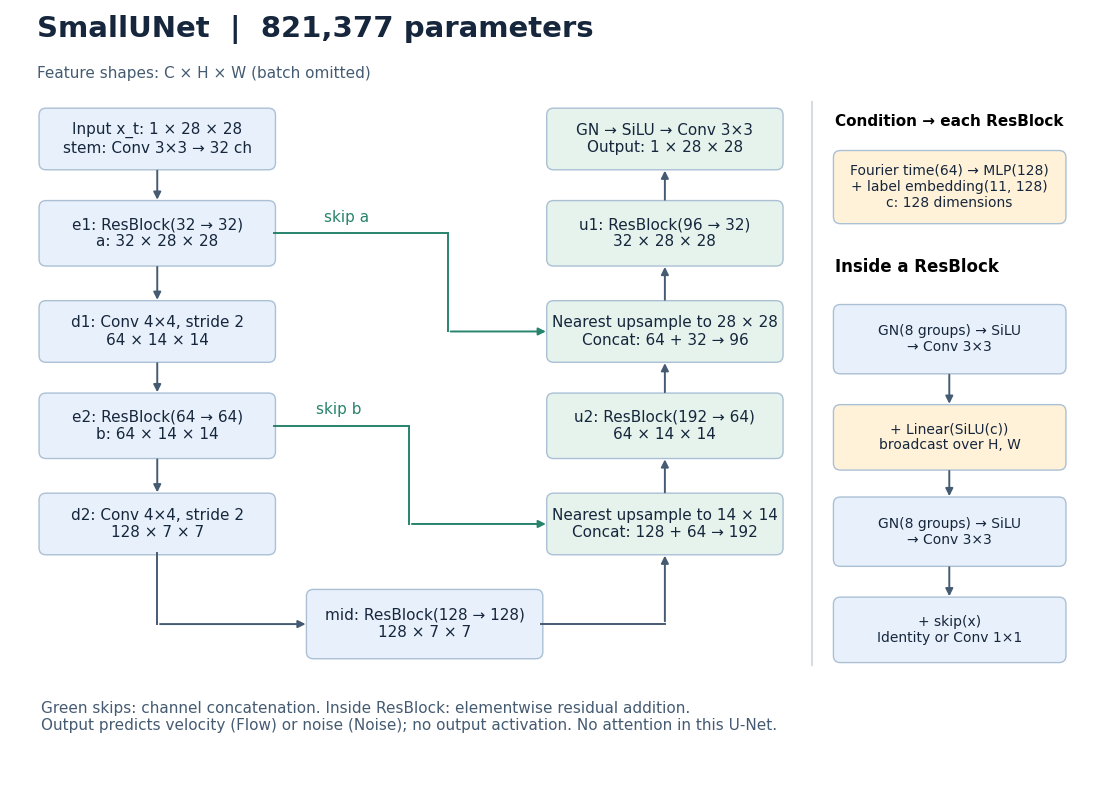

In [ ]:
#@title UNET architecture — implementation diagram
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def architecture_canvas(title):
    fig, ax = plt.subplots(figsize=(14, 10))
    fig.patch.set_facecolor('white'); ax.set_facecolor('white')
    ax.set(xlim=(0,14),ylim=(0,10)); ax.axis('off')
    ax.text(.35,9.65,title,fontsize=21,weight='bold',color='#16263c')
    return fig,ax

def box(ax,x,y,w,h,text,color='#e8f1fb',size=11):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.025,rounding_size=.09',
                              facecolor=color,edgecolor='#abc0d5',linewidth=1))
    ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=size,color='#16263c')

def arrow(ax,points,color='#455b72',dashed=False):
    for a,b in zip(points[:-2],points[1:-1]):
        ax.plot([a[0],b[0]],[a[1],b[1]],color=color,lw=1.4,ls='--' if dashed else '-')
    ax.add_patch(FancyArrowPatch(points[-2],points[-1],arrowstyle='-|>',mutation_scale=11,
                               lw=1.4,color=color,linestyle='--' if dashed else '-'))

def draw_unet():
    fig,ax=architecture_canvas('SmallUNet  |  821,377 parameters')
    ax.text(.35,9.12,'Feature shapes: C × H × W (batch omitted)',fontsize=11,color='#455b72')
    box(ax,.4,7.95,3,.75,'Input x_t: 1 × 28 × 28\nstem: Conv 3×3 → 32 ch')
    box(ax,.4,6.7,3,.8,'e1: ResBlock(32 → 32)\na: 32 × 28 × 28')
    box(ax,.4,5.45,3,.75,'d1: Conv 4×4, stride 2\n64 × 14 × 14')
    box(ax,.4,4.2,3,.8,'e2: ResBlock(64 → 64)\nb: 64 × 14 × 14')
    box(ax,.4,2.95,3,.75,'d2: Conv 4×4, stride 2\n128 × 7 × 7')
    box(ax,3.85,1.6,3,.85,'mid: ResBlock(128 → 128)\n128 × 7 × 7')
    box(ax,6.95,2.95,3,.75,'Nearest upsample to 14 × 14\nConcat: 128 + 64 → 192',color='#e5f3ec')
    box(ax,6.95,4.2,3,.8,'u2: ResBlock(192 → 64)\n64 × 14 × 14',color='#e5f3ec')
    box(ax,6.95,5.45,3,.75,'Nearest upsample to 28 × 28\nConcat: 64 + 32 → 96',color='#e5f3ec')
    box(ax,6.95,6.7,3,.8,'u1: ResBlock(96 → 32)\n32 × 28 × 28',color='#e5f3ec')
    box(ax,6.95,7.95,3,.75,'GN → SiLU → Conv 3×3\nOutput: 1 × 28 × 28',color='#e5f3ec')
    for yt,yb in [(7.95,7.5),(6.7,6.2),(5.45,5),(4.2,3.7)]:arrow(ax,[(1.9,yt),(1.9,yb)])
    arrow(ax,[(1.9,2.95),(1.9,2.025),(3.85,2.025)])
    arrow(ax,[(6.85,2.025),(8.45,2.025),(8.45,2.95)])
    for yb,yt in [(3.7,4.2),(5,5.45),(6.2,6.7),(7.5,7.95)]:arrow(ax,[(8.45,yb),(8.45,yt)])
    arrow(ax,[(3.4,7.1),(5.65,7.1),(5.65,5.825),(6.95,5.825)],'#27836c')
    ax.text(4.05,7.25,'skip a',fontsize=11,color='#27836c')
    arrow(ax,[(3.4,4.6),(5.15,4.6),(5.15,3.325),(6.95,3.325)],'#27836c')
    ax.text(3.95,4.75,'skip b',fontsize=11,color='#27836c')
    ax.plot([10.35,10.35],[1.5,8.8],color='#d4dce4')
    ax.text(10.65,8.5,'Condition → each ResBlock',fontsize=11,weight='bold')
    box(ax,10.65,7.25,2.95,.9,'Fourier time(64) → MLP(128)\n+ label embedding(11, 128)\nc: 128 dimensions','#fff2d9',10)
    ax.text(10.65,6.6,'Inside a ResBlock',fontsize=12,weight='bold')
    box(ax,10.65,5.3,2.95,.85,'GN(8 groups) → SiLU\n→ Conv 3×3',size=10)
    box(ax,10.65,4.05,2.95,.8,'+ Linear(SiLU(c))\nbroadcast over H, W','#fff2d9',10)
    box(ax,10.65,2.8,2.95,.85,'GN(8 groups) → SiLU\n→ Conv 3×3',size=10)
    box(ax,10.65,1.55,2.95,.8,'+ skip(x)\nIdentity or Conv 1×1',size=10)
    for yt,yb in [(5.3,4.85),(4.05,3.65),(2.8,2.35)]:arrow(ax,[(12.12,yt),(12.12,yb)])
    ax.text(.4,.65,'Green skips: channel concatenation. Inside ResBlock: elementwise residual addition.\nOutput predicts velocity (Flow) or noise (Noise); no output activation. No attention in this U-Net.',fontsize=11,color='#455b72')
    return fig

def draw_dit():
    fig,ax=architecture_canvas('SmallDiT  |  2,807,248 parameters')
    ax.text(.35,9.12,'Token shapes: N × D (batch omitted) • pixel-space model',fontsize=11,color='#455b72')
    left=[('Input x_t\n1 × 28 × 28',8.0),('Patch Conv 4×4, stride 4\n192 × 7 × 7',6.85),('Flatten + transpose\n49 tokens × 192 features',5.7),('+ learned position embedding\n1 × 49 × 192',4.55),('4 × DiTBlock\n49 × 192 throughout',3.4),('Final LayerNorm + adaLN\nLinear: 192 → 16 per patch',2.25),('Unpatchify 49 patches of 4×4\nOutput: 1 × 28 × 28',1.1)]
    for text,y in left:box(ax,.4,y,4,.8,text)
    for (_,yt),(_,yb) in zip(left[:-1],left[1:]):arrow(ax,[(2.4,yt),(2.4,yb+.8)])
    ax.plot([4.85,4.85],[1,8.9],color='#d4dce4')
    ax.text(5.2,8.65,'One DiTBlock (repeated 4 times)',fontsize=13,weight='bold')
    bx,by,bw=6.2,7.4,3.6
    stages=[('h: 49 × 192',7.4),('LayerNorm → shift / scale',6.35),('Self-attention · 6 heads',5.3),('× gate₁ + residual h',4.25),('LayerNorm → shift / scale',3.2),('MLP: 192 → 768 → 192\nGELU activation',2.15),('× gate₂ + residual',1.1)]
    for text,y in stages:box(ax,bx,y,bw,.7,text,'#e5f3ec',11)
    for (_,yt),(_,yb) in zip(stages[:-1],stages[1:]):arrow(ax,[(8,yt),(8,yb+.7)])
    arrow(ax,[(6.2,7.75),(5.45,7.75),(5.45,4.6),(6.2,4.6)],'#27836c')
    arrow(ax,[(6.2,4.6),(5.7,4.6),(5.7,1.45),(6.2,1.45)],'#27836c')
    box(ax,10.4,7.4,3.15,.95,'Time MLP + label embedding\nc: 192 dimensions','#fff2d9',10)
    box(ax,10.4,5.9,3.15,1.,'SiLU → Linear(192, 6×192)\nshift₁, scale₁, gate₁\nshift₂, scale₂, gate₂','#fff2d9',10)
    arrow(ax,[(11.975,7.4),(11.975,6.9)],'#b88828')
    for y in [6.7,4.6,3.55,1.45]:
        arrow(ax,[(10.4,6.15),(10.1,6.15),(10.1,y),(9.8,y)],'#b88828',True)
    box(ax,10.4,3.4,3.15,1.2,'adaLN(h, c)\nLN(h) × (1 + scale(c))\n+ shift(c)','#fff2d9',10)
    ax.text(10.4,2.75,'adaLN-Zero',fontsize=12,weight='bold')
    ax.text(10.4,2.25,'Modulation / gate layers\nand final output head\nare zero-initialized.',fontsize=10,color='#455b72',va='top')
    ax.text(.4,.35,'Final adaLN also receives c. Flow / Noise share this architecture; only the training target changes.',fontsize=11,color='#455b72')
    return fig

fig = draw_unet()
plt.show()


In [ ]:
class ResBlock(nn.Module):
    def __init__(self,ci,co,cond=128):
        super().__init__()
        self.n1=nn.GroupNorm(8,ci); self.c1=nn.Conv2d(ci,co,3,padding=1)
        self.emb=nn.Linear(cond,co)
        self.n2=nn.GroupNorm(8,co); self.c2=nn.Conv2d(co,co,3,padding=1)
        self.skip=nn.Conv2d(ci,co,1) if ci!=co else nn.Identity()
    def forward(self,x,c):
        h=self.c1(F.silu(self.n1(x)))+self.emb(F.silu(c))[:,:,None,None]
        return self.skip(x)+self.c2(F.silu(self.n2(h)))

class SmallUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.cond=Condition(128); self.stem=nn.Conv2d(1,32,3,padding=1)
        self.e1=ResBlock(32,32); self.d1=nn.Conv2d(32,64,4,2,1)
        self.e2=ResBlock(64,64); self.d2=nn.Conv2d(64,128,4,2,1)
        self.mid=ResBlock(128,128)
        self.u2=ResBlock(128+64,64); self.u1=ResBlock(64+32,32)
        self.out=nn.Sequential(nn.GroupNorm(8,32),nn.SiLU(),nn.Conv2d(32,1,3,padding=1))
        nn.init.zeros_(self.out[-1].weight); nn.init.zeros_(self.out[-1].bias)
    def forward(self,x,t,y):
        c=self.cond(t,y)
        a=self.e1(self.stem(x),c); b=self.e2(self.d1(a),c)
        h=self.mid(self.d2(b),c)
        h=self.u2(torch.cat([F.interpolate(h,size=b.shape[-2:],mode='nearest'),b],1),c)
        h=self.u1(torch.cat([F.interpolate(h,size=a.shape[-2:],mode='nearest'),a],1),c)
        return self.out(h)


## 4. DiT: 49개 patch token을 처리하기

DiT는 이미지를 patch token으로 바꾼 뒤 Transformer로 처리한다. 이 구현은 28×28 이미지를 겹치지 않는 4×4 patch 49개로 나누고, 각 patch를 192차원 token으로 변환한다. **Self-attention은 49개 patch 사이의 정보를 교환**하므로 서로 떨어진 위치의 특징도 함께 활용할 수 있다.

| 단계 | shape (batch 생략) | 연산과 역할 |
|---|---|---|
| Patch embedding | 49×192 | kernel 4, stride 4 convolution으로 patch를 token으로 변환 |
| Position embedding | 49×192 | 학습 가능한 위치 embedding을 더해 patch 위치 표시 |
| Transformer blocks ×4 | 49×192 | 각 block에서 6-head self-attention과 MLP로 token 처리 |
| Output projection | 49×16 | 최종 정규화와 조건 반영 후 patch당 16개 픽셀 값 예측 |
| Unpatchify | 1×28×28 | patch 출력을 원래 공간 위치에 재배열 |

학습 가능한 position embedding의 parameter shape은 `[1,49,192]`이며 batch 전체에 공유한다. 별도의 이미지 encoder나 latent space를 사용하지 않고 픽셀 공간에서 직접 예측하는 소규모 DiT이다.

시간과 클래스 embedding을 합친 condition $c$는 **adaptive LayerNorm(adaLN)** 을 통해 각 block에 반영한다.

$$
\operatorname{adaLN}(h,c)=\operatorname{LN}(h)\odot(1+\gamma(c))+\beta(c)
$$

Condition으로부터 얻은 $\gamma(c)$와 $\beta(c)$가 정규화된 특징의 크기와 위치를 조절한다. 이 값들은 채널별로 적용되며 모든 token에 공유된다. Attention과 MLP는 각각 별도의 scale·shift·gate를 사용하고, gate $g(c)$는 residual branch의 기여도를 조절한다.

$$
h_{\mathrm{out}}=h+g(c)\odot F\bigl(\operatorname{adaLN}(h,c)\bigr)
$$

여기서 $F$는 self-attention 또는 MLP이다. **adaLN-Zero** 방식으로 modulation·gate를 만드는 선형층을 0으로 초기화하여 각 Transformer block이 처음에는 identity로 동작하도록 한다. 최종 adaLN의 modulation 선형층과 출력 projection도 0으로 초기화하므로 초기 모델 출력은 0이다. 첫 gradient update에서는 출력 projection부터 학습되고, 이후 앞쪽 층으로도 gradient가 전달된다.

**U-Net과 DiT 모두 Flow와 Noise 둘 다 사용할 수 있다.** 두 경우 출력 shape은 같으며, 학습 target과 sampling 시 출력의 해석이 달라진다.


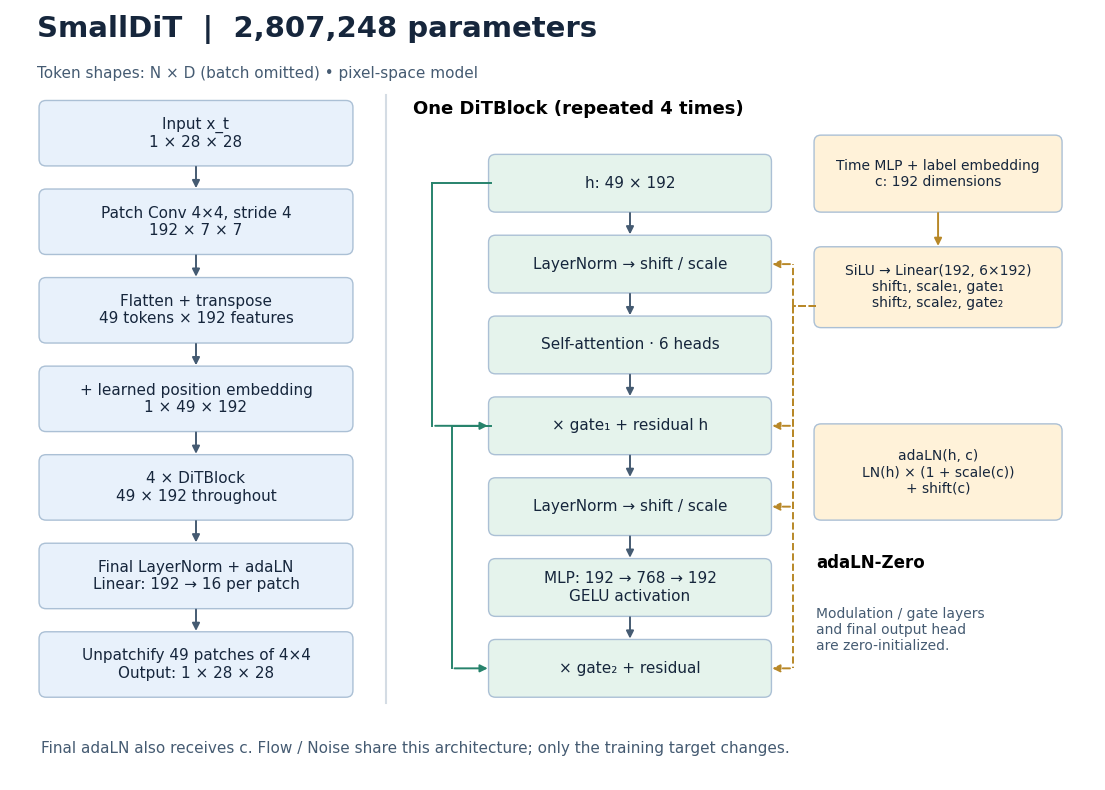

In [ ]:
#@title DIT architecture — implementation diagram
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def architecture_canvas(title):
    fig, ax = plt.subplots(figsize=(14, 10))
    fig.patch.set_facecolor('white'); ax.set_facecolor('white')
    ax.set(xlim=(0,14),ylim=(0,10)); ax.axis('off')
    ax.text(.35,9.65,title,fontsize=21,weight='bold',color='#16263c')
    return fig,ax

def box(ax,x,y,w,h,text,color='#e8f1fb',size=11):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.025,rounding_size=.09',
                              facecolor=color,edgecolor='#abc0d5',linewidth=1))
    ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=size,color='#16263c')

def arrow(ax,points,color='#455b72',dashed=False):
    for a,b in zip(points[:-2],points[1:-1]):
        ax.plot([a[0],b[0]],[a[1],b[1]],color=color,lw=1.4,ls='--' if dashed else '-')
    ax.add_patch(FancyArrowPatch(points[-2],points[-1],arrowstyle='-|>',mutation_scale=11,
                               lw=1.4,color=color,linestyle='--' if dashed else '-'))

def draw_unet():
    fig,ax=architecture_canvas('SmallUNet  |  821,377 parameters')
    ax.text(.35,9.12,'Feature shapes: C × H × W (batch omitted)',fontsize=11,color='#455b72')
    box(ax,.4,7.95,3,.75,'Input x_t: 1 × 28 × 28\nstem: Conv 3×3 → 32 ch')
    box(ax,.4,6.7,3,.8,'e1: ResBlock(32 → 32)\na: 32 × 28 × 28')
    box(ax,.4,5.45,3,.75,'d1: Conv 4×4, stride 2\n64 × 14 × 14')
    box(ax,.4,4.2,3,.8,'e2: ResBlock(64 → 64)\nb: 64 × 14 × 14')
    box(ax,.4,2.95,3,.75,'d2: Conv 4×4, stride 2\n128 × 7 × 7')
    box(ax,3.85,1.6,3,.85,'mid: ResBlock(128 → 128)\n128 × 7 × 7')
    box(ax,6.95,2.95,3,.75,'Nearest upsample to 14 × 14\nConcat: 128 + 64 → 192',color='#e5f3ec')
    box(ax,6.95,4.2,3,.8,'u2: ResBlock(192 → 64)\n64 × 14 × 14',color='#e5f3ec')
    box(ax,6.95,5.45,3,.75,'Nearest upsample to 28 × 28\nConcat: 64 + 32 → 96',color='#e5f3ec')
    box(ax,6.95,6.7,3,.8,'u1: ResBlock(96 → 32)\n32 × 28 × 28',color='#e5f3ec')
    box(ax,6.95,7.95,3,.75,'GN → SiLU → Conv 3×3\nOutput: 1 × 28 × 28',color='#e5f3ec')
    for yt,yb in [(7.95,7.5),(6.7,6.2),(5.45,5),(4.2,3.7)]:arrow(ax,[(1.9,yt),(1.9,yb)])
    arrow(ax,[(1.9,2.95),(1.9,2.025),(3.85,2.025)])
    arrow(ax,[(6.85,2.025),(8.45,2.025),(8.45,2.95)])
    for yb,yt in [(3.7,4.2),(5,5.45),(6.2,6.7),(7.5,7.95)]:arrow(ax,[(8.45,yb),(8.45,yt)])
    arrow(ax,[(3.4,7.1),(5.65,7.1),(5.65,5.825),(6.95,5.825)],'#27836c')
    ax.text(4.05,7.25,'skip a',fontsize=11,color='#27836c')
    arrow(ax,[(3.4,4.6),(5.15,4.6),(5.15,3.325),(6.95,3.325)],'#27836c')
    ax.text(3.95,4.75,'skip b',fontsize=11,color='#27836c')
    ax.plot([10.35,10.35],[1.5,8.8],color='#d4dce4')
    ax.text(10.65,8.5,'Condition → each ResBlock',fontsize=11,weight='bold')
    box(ax,10.65,7.25,2.95,.9,'Fourier time(64) → MLP(128)\n+ label embedding(11, 128)\nc: 128 dimensions','#fff2d9',10)
    ax.text(10.65,6.6,'Inside a ResBlock',fontsize=12,weight='bold')
    box(ax,10.65,5.3,2.95,.85,'GN(8 groups) → SiLU\n→ Conv 3×3',size=10)
    box(ax,10.65,4.05,2.95,.8,'+ Linear(SiLU(c))\nbroadcast over H, W','#fff2d9',10)
    box(ax,10.65,2.8,2.95,.85,'GN(8 groups) → SiLU\n→ Conv 3×3',size=10)
    box(ax,10.65,1.55,2.95,.8,'+ skip(x)\nIdentity or Conv 1×1',size=10)
    for yt,yb in [(5.3,4.85),(4.05,3.65),(2.8,2.35)]:arrow(ax,[(12.12,yt),(12.12,yb)])
    ax.text(.4,.65,'Green skips: channel concatenation. Inside ResBlock: elementwise residual addition.\nOutput predicts velocity (Flow) or noise (Noise); no output activation. No attention in this U-Net.',fontsize=11,color='#455b72')
    return fig

def draw_dit():
    fig,ax=architecture_canvas('SmallDiT  |  2,807,248 parameters')
    ax.text(.35,9.12,'Token shapes: N × D (batch omitted) • pixel-space model',fontsize=11,color='#455b72')
    left=[('Input x_t\n1 × 28 × 28',8.0),('Patch Conv 4×4, stride 4\n192 × 7 × 7',6.85),('Flatten + transpose\n49 tokens × 192 features',5.7),('+ learned position embedding\n1 × 49 × 192',4.55),('4 × DiTBlock\n49 × 192 throughout',3.4),('Final LayerNorm + adaLN\nLinear: 192 → 16 per patch',2.25),('Unpatchify 49 patches of 4×4\nOutput: 1 × 28 × 28',1.1)]
    for text,y in left:box(ax,.4,y,4,.8,text)
    for (_,yt),(_,yb) in zip(left[:-1],left[1:]):arrow(ax,[(2.4,yt),(2.4,yb+.8)])
    ax.plot([4.85,4.85],[1,8.9],color='#d4dce4')
    ax.text(5.2,8.65,'One DiTBlock (repeated 4 times)',fontsize=13,weight='bold')
    bx,by,bw=6.2,7.4,3.6
    stages=[('h: 49 × 192',7.4),('LayerNorm → shift / scale',6.35),('Self-attention · 6 heads',5.3),('× gate₁ + residual h',4.25),('LayerNorm → shift / scale',3.2),('MLP: 192 → 768 → 192\nGELU activation',2.15),('× gate₂ + residual',1.1)]
    for text,y in stages:box(ax,bx,y,bw,.7,text,'#e5f3ec',11)
    for (_,yt),(_,yb) in zip(stages[:-1],stages[1:]):arrow(ax,[(8,yt),(8,yb+.7)])
    arrow(ax,[(6.2,7.75),(5.45,7.75),(5.45,4.6),(6.2,4.6)],'#27836c')
    arrow(ax,[(6.2,4.6),(5.7,4.6),(5.7,1.45),(6.2,1.45)],'#27836c')
    box(ax,10.4,7.4,3.15,.95,'Time MLP + label embedding\nc: 192 dimensions','#fff2d9',10)
    box(ax,10.4,5.9,3.15,1.,'SiLU → Linear(192, 6×192)\nshift₁, scale₁, gate₁\nshift₂, scale₂, gate₂','#fff2d9',10)
    arrow(ax,[(11.975,7.4),(11.975,6.9)],'#b88828')
    for y in [6.7,4.6,3.55,1.45]:
        arrow(ax,[(10.4,6.15),(10.1,6.15),(10.1,y),(9.8,y)],'#b88828',True)
    box(ax,10.4,3.4,3.15,1.2,'adaLN(h, c)\nLN(h) × (1 + scale(c))\n+ shift(c)','#fff2d9',10)
    ax.text(10.4,2.75,'adaLN-Zero',fontsize=12,weight='bold')
    ax.text(10.4,2.25,'Modulation / gate layers\nand final output head\nare zero-initialized.',fontsize=10,color='#455b72',va='top')
    ax.text(.4,.35,'Final adaLN also receives c. Flow / Noise share this architecture; only the training target changes.',fontsize=11,color='#455b72')
    return fig

fig = draw_dit()
plt.show()


In [ ]:
def modulate(h,shift,scale): return h*(1+scale[:,None])+shift[:,None]
class DiTBlock(nn.Module):
    def __init__(self,d=192,heads=6):
        super().__init__()
        self.n1=nn.LayerNorm(d,elementwise_affine=False)
        self.n2=nn.LayerNorm(d,elementwise_affine=False)
        self.attn=nn.MultiheadAttention(d,heads,batch_first=True,dropout=0)
        self.mlp=nn.Sequential(nn.Linear(d,4*d),nn.GELU(),nn.Linear(4*d,d))
        self.ada=nn.Sequential(nn.SiLU(),nn.Linear(d,6*d))
        nn.init.zeros_(self.ada[-1].weight); nn.init.zeros_(self.ada[-1].bias)
    def forward(self,h,c):
        s1,a1,g1,s2,a2,g2=self.ada(c).chunk(6,dim=1)
        q=modulate(self.n1(h),s1,a1)
        h=h+g1[:,None]*self.attn(q,q,q,need_weights=False)[0]
        return h+g2[:,None]*self.mlp(modulate(self.n2(h),s2,a2))

class SmallDiT(nn.Module):
    def __init__(self,d=192,depth=4,p=4):
        super().__init__(); self.p=p
        self.cond=Condition(d); self.patch=nn.Conv2d(1,d,p,stride=p)
        self.pos=nn.Parameter(torch.randn(1,49,d)*.02)
        self.blocks=nn.ModuleList([DiTBlock(d) for _ in range(depth)])
        self.norm=nn.LayerNorm(d,elementwise_affine=False)
        self.ada=nn.Sequential(nn.SiLU(),nn.Linear(d,2*d)); self.out=nn.Linear(d,p*p)
        for layer in [self.ada[-1],self.out]:
            nn.init.zeros_(layer.weight); nn.init.zeros_(layer.bias)
    def forward(self,x,t,y):
        c=self.cond(t,y); h=self.patch(x).flatten(2).transpose(1,2)+self.pos
        for block in self.blocks: h=block(h,c)
        shift,scale=self.ada(c).chunk(2,1)
        h=self.out(modulate(self.norm(h),shift,scale))
        # [B,7,7,patch_row,patch_col] → [B,1,28,28]
        return h.reshape(-1,7,7,self.p,self.p).permute(0,1,3,2,4).reshape(-1,1,28,28)

def make_model(arch):
    return {'unet':SmallUNet, 'dit':SmallDiT}[arch]()


## 5. 모델 크기 비교

| Architecture | Parameter 수 |
|---|---:|
| U-Net | 821,377 |
| DiT | 2,807,248 |

이 구현에서 DiT의 parameter 수는 U-Net의 약 **3.42배**이다. 각 architecture에서 Flow와 Noise 모델은 같은 구조를 사용하므로 parameter 수도 같다.


## 6. 학습과 checkpoint 선택

U-Net과 DiT를 각각 Flow 및 Noise target으로 30 epoch 학습한다. 같은 architecture의 두 모델은 동일한 seed로 초기화하고, epoch별 난수 seed를 고정하여 데이터 순서·시간·noise·label dropout을 동일하게 적용한다.

학습에는 batch size 64, FP32, AdamW(learning rate $2\times10^{-4}$, weight decay $10^{-4}$)를 사용한다. Learning rate는 일정하게 유지하고 gradient norm을 1.0으로 제한한다. EMA는 사용하지 않는다.

매 epoch 고정된 validation 입력에서 각 모델의 target에 대한 MSE를 계산한다. **Sampling과 평가는 모델별 validation MSE가 가장 낮았던 `best.pt`를 사용한다.** 따라서 모델마다 선택되는 epoch는 다를 수 있다. Flow와 Noise의 MSE를 서로 비교해 checkpoint를 선택하는 것이 아니라, 각 모델의 학습 이력 안에서 최솟값을 선택한다.

| Checkpoint | 저장 기준 | 용도 |
|---|---|---|
| `last.pt` | 매 epoch 갱신 | 모델·optimizer·완료 epoch를 복원하여 학습 재개 |
| `best.pt` | Validation MSE가 이전 최솟값보다 낮을 때 갱신 | 이미지 생성, ODE/SDE 평가, 시간별 오차 분석 및 모델 교체 실험 |

학습 재개 시에는 저장된 설정을 확인하고 `last.pt`에서 이어서 학습한다. 생성·평가에는 `best.pt`의 parameter를 그대로 사용한다.


In [ ]:
def synchronize():
    if device.type=='cuda': torch.cuda.synchronize()

def atomic_save(state,path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_suffix('.tmp'); torch.save(state,tmp); os.replace(tmp,path)

def config(arch,kind):
    return dict(version='lab03_v1',arch=arch,kind=kind,seed=SEED,batch=BATCH,
                lr=LR,label_drop=LABEL_DROP,weight_decay=1e-4)

def ckpt_path(arch,kind): return RUN_DIR/f'{arch}_{kind}'/'last.pt'

def batch_path(z,y,rng,drop):
    t=torch.rand(len(z),generator=rng)
    eps=torch.randn(z.shape,generator=rng)
    yy=y.clone()
    if drop: yy[torch.rand(len(y),generator=rng)<LABEL_DROP]=NULL_LABEL
    tt=t[:,None,None,None]
    return (tt*z+(1-tt)*eps).to(device),t.to(device),yy.to(device),eps.to(device)

@torch.no_grad()
def validation(m,kind):
    m.eval(); rng=torch.Generator().manual_seed(12345); total=0.; count=0
    for z,y in val_loader:
        x,t,yy,eps=batch_path(z,y,rng,False)
        target=z.to(device)-eps if kind=='flow' else eps
        total+=F.mse_loss(m(x,t,yy),target).item()*len(z); count+=len(z)
    return total/count

def train_one(arch,kind):
    torch.manual_seed(SEED)
    m=make_model(arch).to(device); opt=torch.optim.AdamW(m.parameters(),lr=LR,weight_decay=1e-4)
    path=ckpt_path(arch,kind); start_epoch=0; history=[]; best=float('inf')
    if path.exists():
        if not RESUME: raise FileExistsError('기존 결과 보호: RESUME=True 또는 새 RUN_NAME 사용')
        state=torch.load(path,map_location=device,weights_only=True)
        assert state['config']==config(arch,kind), '설정 변경 시 새 RUN_NAME 사용'
        m.load_state_dict(state['model']); opt.load_state_dict(state['optimizer'])
        start_epoch=state['epoch']; history=state['history']; best=state['best']
        del state
    if not TRAIN:
        if not path.exists(): raise FileNotFoundError(f'학습된 checkpoint 없음: {path}')
        print(arch,kind,'loaded epoch',start_epoch); return
    for epoch in range(start_epoch,EPOCHS):
        loader=DataLoader(train_ds,batch_size=BATCH,shuffle=True,
            generator=torch.Generator().manual_seed(SEED+epoch),num_workers=0)
        rng=torch.Generator().manual_seed(SEED+10000+epoch)
        m.train(); total=0.; count=0; synchronize(); tic=time.perf_counter()
        for z,y in loader:
            x,t,yy,eps=batch_path(z,y,rng,True)
            target=z.to(device)-eps if kind=='flow' else eps
            opt.zero_grad(set_to_none=True)
            loss=F.mse_loss(m(x,t,yy),target)
            if not torch.isfinite(loss): raise RuntimeError('Non-finite loss; 설정과 LR 확인')
            loss.backward(); nn.utils.clip_grad_norm_(m.parameters(),1.0); opt.step()
            total+=loss.item()*len(z); count+=len(z)
        val=validation(m,kind); synchronize()
        history.append(dict(epoch=epoch+1,train=total/count,val=val,seconds=time.perf_counter()-tic))
        improved=val<best; best=min(best,val)
        state=dict(config=config(arch,kind),epoch=epoch+1,model=m.state_dict(),
                   optimizer=opt.state_dict(),history=history,best=best)
        atomic_save(state,path)
        if improved: atomic_save(state,path.with_name('best.pt'))
        pd.DataFrame(history).to_csv(path.with_name('history.csv'),index=False)
        print(arch,kind,history[-1],flush=True)
    print('완료:',path)

for arch,kind in EXPERIMENTS:
    train_one(arch,kind); gc.collect()
    if device.type=='cuda': torch.cuda.empty_cache()


완료: /content/drive/MyDrive/MNIST_Architecture_Lab03/run_v1/unet_flow/last.pt
완료: /content/drive/MyDrive/MNIST_Architecture_Lab03/run_v1/dit_flow/last.pt
완료: /content/drive/MyDrive/MNIST_Architecture_Lab03/run_v1/unet_noise/last.pt
완료: /content/drive/MyDrive/MNIST_Architecture_Lab03/run_v1/dit_noise/last.pt


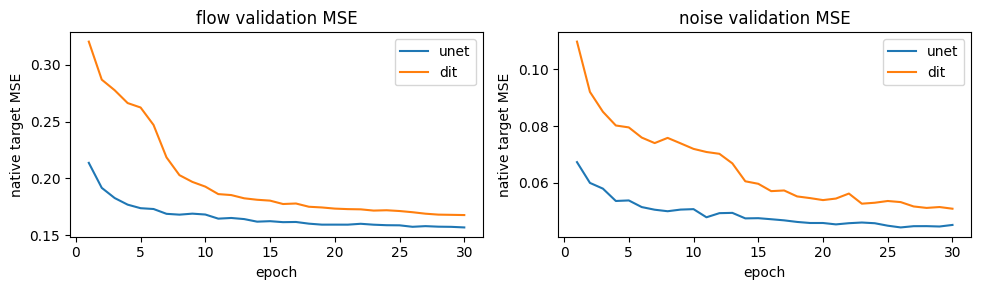

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(10,3))
for arch,kind in EXPERIMENTS:
    p=ckpt_path(arch,kind).with_name('history.csv')
    if p.exists():
        h=pd.read_csv(p); ax=axes[['flow','noise'].index(kind)]
        ax.plot(h.epoch,h.val,label=arch)
for ax,kind in zip(axes,['flow','noise']):
    ax.set(title=kind+' validation MSE',xlabel='epoch',ylabel='native target MSE')
    if ax.lines: ax.legend()
plt.tight_layout(); plt.show()


## 7. 모델 출력으로 이미지를 생성하기: ODE와 SDE

생성은 Gaussian noise에서 출발해 이미지를 점차 완성하는 과정이다. 학습에 사용한 경로는 $x_t=t z+(1-t)\epsilon$이므로, 시간 $t$가 0에서 1로 증가할수록 noise에서 이미지로 이동한다. 이 절에서는 모델의 출력을 현재 이미지의 이동 방향인 **velocity**로 바꾸고, 이를 이용해 ODE와 SDE sampling을 구현한다.

### 모델 출력을 velocity와 score로 변환하기

아래에서 $x$는 현재 생성 중인 이미지 $x_t$, $f_w$는 CFG를 적용한 모델 출력이다. CFG는 label 없이 예측한 출력과 원하는 숫자 label을 주고 예측한 출력을 조합한다.

$$
f_w=f_\theta(x,t,\varnothing)+w\bigl[f_\theta(x,t,y)-f_\theta(x,t,\varnothing)\bigr]
$$

$w=1$이면 label을 준 모델의 출력을 그대로 사용하고, $w>1$이면 label의 영향을 더 강하게 반영한다.

Flow 모델은 velocity를 직접 예측한다. Noise 모델은 noise를 예측하므로, $x_t-\epsilon=t(z-\epsilon)$ 관계를 이용해 velocity로 변환한다.

**Score** $s=\nabla_x\log p_t(x)$는 현재 시간의 분포에서 확률밀도가 높아지는 방향을 나타내며, 아래 SDE의 이동 방향을 보정하는 데 사용한다. 이 경로에 대한 변환식은 다음과 같다($0<t<1$).

**Flow 출력 $f_w$**

$$
v=f_w,\qquad s=\frac{tv-x}{1-t}
$$

**Noise 출력 $f_w$**

$$
v=\frac{x-f_w}{t},\qquad s=-\frac{f_w}{1-t}
$$

### ODE와 SDE의 차이

**ODE**는 velocity가 가리키는 방향으로 이미지를 이동시킨다.

$$
dx=v\,dt
$$

**SDE**는 이동 과정에 random noise를 추가한다. Noise만 추가하면 시간에 따른 이미지 분포의 변화도 달라지므로, **원래의 probability path를 유지하기 위해 drift(이동 방향)도 score를 이용해 보정한다.**

$$
dx=\left[v+\frac12g(t)^2s\right]dt+g(t)dW_t
$$

같은 초기분포에서 시작하고, 그 경로에 대한 정확한 velocity와 score를 사용하면 ODE와 SDE는 **각 시간에 같은 이미지 분포**를 만든다. 이것이 같은 probability path를 유지한다는 뜻이다. 개별 이미지가 이동하는 경로까지 같다는 의미는 아니다. 이 관계는 수치적으로 step을 나누기 전의 연속시간 식을 기준으로 한다.

이번 구현에서는 $g(t)^2=2\kappa(1-t)$로 설정한다. $\kappa$는 추가하는 noise의 강도를 조절하며, 이미지가 완성되는 $t=1$에 가까워질수록 noise가 줄어든다. 위의 score 식을 대입하면 drift는 다음처럼 정리된다.

$$
v+\frac12g(t)^2s
=v+\kappa(1-t)\frac{tv-x}{1-t}
=v+\kappa(tv-x)
$$

코드는 이 마지막 식을 사용한다. 따라서 SDE 보정항을 계산할 때 $1-t$로 나누는 연산을 피할 수 있다.

**CFG로 클래스 조건을 더 강하게 적용하는 경우에는 이론과 실제 결과를 구분해야 한다.** $w>1$은 원하는 숫자에 더 가깝게 생성하도록 조건부·무조건부 모델의 출력을 조합하는 설정이다. 이렇게 강화한 velocity와 score에 대해서는 위의 probability path 유지 관계가 자동으로 성립하지 않는다. 따라서 ODE와 SDE가 같은 생성 분포를 만든다고 단정할 수는 없다. 실제 결과에는 guidance 강도뿐 아니라 모델의 예측 오차와 수치 적분 오차도 영향을 준다.

### 생성 구간과 계산량

출력 변환식에는 $t$ 또는 $1-t$로 나누는 항이 있으므로, 끝점에서의 계산 문제를 피하기 위해 **$t=0.01$에서 시작해 $t=0.99$에서 종료**한다.

시작 상태는 표준 Gaussian noise를 사용한다. 실제 경로의 $x_{0.01}=0.01z+0.99\epsilon$과는 조금 다르지만, 두 sampling 방법 모두 같은 시작 조건을 사용한다. 마지막에는 $t=0.99$의 출력을 그대로 사용하며, 추가 denoising이나 $t=1$까지의 외삽 보정은 하지 않는다.

ODE에는 **Heun 방법**, SDE에는 **Euler–Maruyama 방법**을 사용한다. Heun은 한 step에서 velocity를 두 번 계산하고, Euler–Maruyama는 한 번 계산한다. 또한 velocity를 한 번 구할 때마다 CFG의 조건부·무조건부 모델 출력을 각각 계산한다.

따라서 **ODE 100 steps와 SDE 200 steps는 모두 총 400회의 모델 평가**를 사용한다. 이는 모델 평가 횟수를 맞춘 비교이며, 실행 시간이나 수치 적분 오차까지 같게 맞춘 것은 아니다.

In [ ]:
def best_ckpt_path(arch,kind):
    return ckpt_path(arch,kind).with_name('best.pt')

def load_model(arch,kind):
    p=best_ckpt_path(arch,kind)
    if not p.exists():
        raise FileNotFoundError(f'Best checkpoint not found: {p}')
    state=torch.load(p,map_location='cpu',weights_only=True)
    assert state['config']==config(arch,kind)
    m=make_model(arch); m.load_state_dict(state['model'])
    return m.to(device).eval().requires_grad_(False),state['epoch']

@torch.no_grad()
def velocity(m,kind,x,t,y,w):
    tv=torch.full((len(x),),float(t),device=x.device)
    un=m(x,tv,torch.full_like(y,NULL_LABEL)); co=m(x,tv,y)
    f=un+w*(co-un)
    return f if kind=='flow' else (x-f)/float(t)

@torch.no_grad()
def sample(m,kind,x0,y,w=2.,sampler='ode',steps=100,kappa=.5,seed=2026,t0=.01,t1=.99):
    assert sampler in ['ode','sde'] and 0<t0<t1<1 and steps>0 and kappa>=0
    x=x0.clone().to(device); y=y.to(device)
    times=np.linspace(t0,t1,steps+1)
    rng=torch.Generator(device=device).manual_seed(seed)
    trace=[x.cpu()]; trace_t=[t0]
    for i in range(steps):
        t=float(times[i]); h=float(times[i+1]-times[i]); v=velocity(m,kind,x,t,y,w)
        if sampler=='ode':
            v2=velocity(m,kind,x+h*v,float(times[i+1]),y,w)
            x=x+.5*h*(v+v2)
        else:
            drift=v+kappa*(t*v-x)
            eta=torch.randn(x.shape,device=device,generator=rng)
            x=x+h*drift+math.sqrt(2*kappa*(1-t)*h)*eta
        if not torch.isfinite(x).all(): raise RuntimeError('Sampling non-finite: endpoint/steps/w 확인')
        if (i+1)%max(1,steps//4)==0 or i==steps-1:
            trace.append(x.cpu()); trace_t.append(float(times[i+1]))
    return x.cpu(),trace,trace_t


## 8. 같은 initial noise로 ODE/SDE 비교
행=label 0–9, 열=서로 다른 initial noise. 같은 열의 초기 noise를 label마다 재사용한다. SDE 추가 noise seed도 고정한다. `w=1,2,4`를 비교한 뒤 더 큰 w를 시도한다. 화면만 clipping하며 raw 출력은 그대로 저장한다.


In [ ]:
COLS=5
noise=torch.randn(COLS,1,28,28,generator=torch.Generator().manual_seed(999))
x0=noise.repeat(10,1,1,1); labels=torch.arange(10).repeat_interleave(COLS)
def show_grid(raw,title):
    fig,axes=plt.subplots(10,COLS,figsize=(COLS,10))
    for ax,img in zip(axes.flat,raw): ax.imshow(img[0].clamp(-1,1),cmap='gray',vmin=-1,vmax=1); ax.axis('off')
    fig.suptitle(title); plt.tight_layout(); plt.show()
for arch,kind in EXPERIMENTS:
    model,epoch=load_model(arch,kind)
    for w in [1., 2., 4.]:
        for solver,steps in [('ode',100),('sde',200)]:
            raw,trace,ts=sample(model,kind,x0,labels,w=w,sampler=solver,steps=steps)
            show_grid(raw,f'{arch} {kind} epoch={epoch} {solver} w={w}')
            atomic_save(dict(raw=raw,trace=trace,times=ts,labels=labels,
                settings=dict(w=w,sampler=solver,steps=steps,kappa=.5,t0=.01,t1=.99,seed=2026),epoch=epoch),
                RUN_DIR/f'{arch}_{kind}_{solver}_preview.pt')
    del model; gc.collect()
    if device.type=='cuda': torch.cuda.empty_cache()


Output hidden; open in https://colab.research.google.com to view.

### 8.1 생성 trajectory
아래는 label 7의 첫 sample을 시간별로 보여준다. 위 preview를 다시 학습할 필요 없이 읽는다. 행은 ODE/SDE, 열은 생성 시간이다.


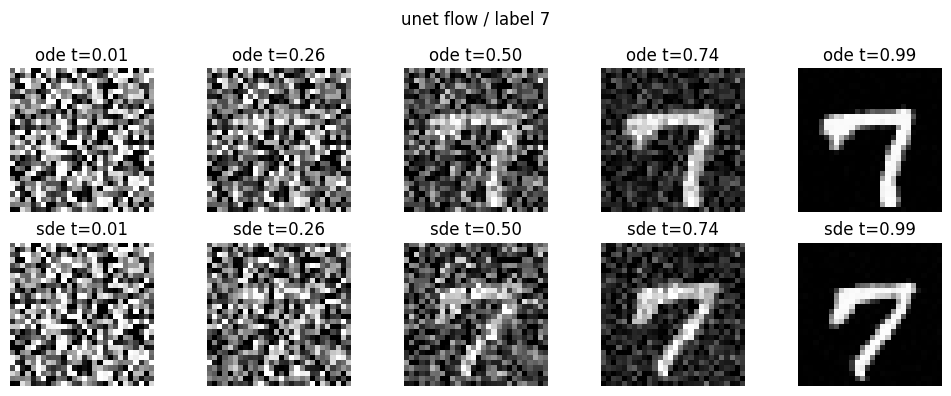

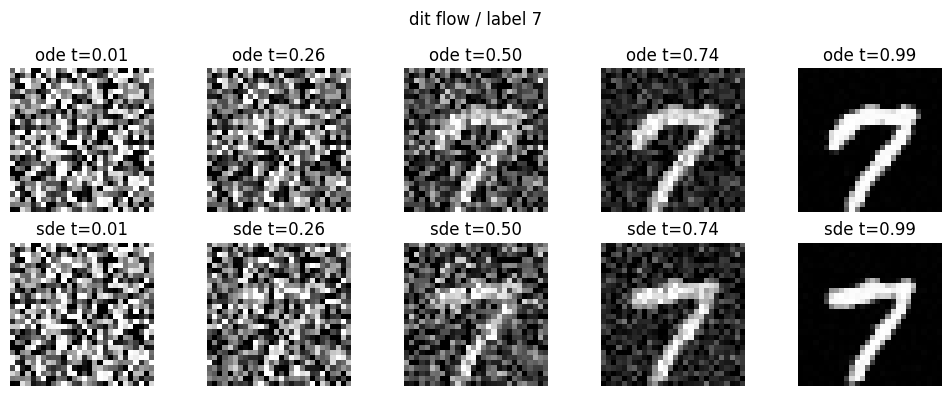

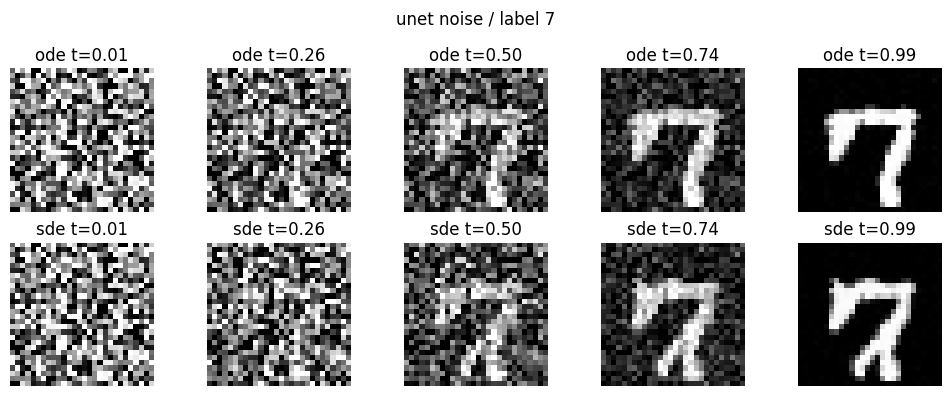

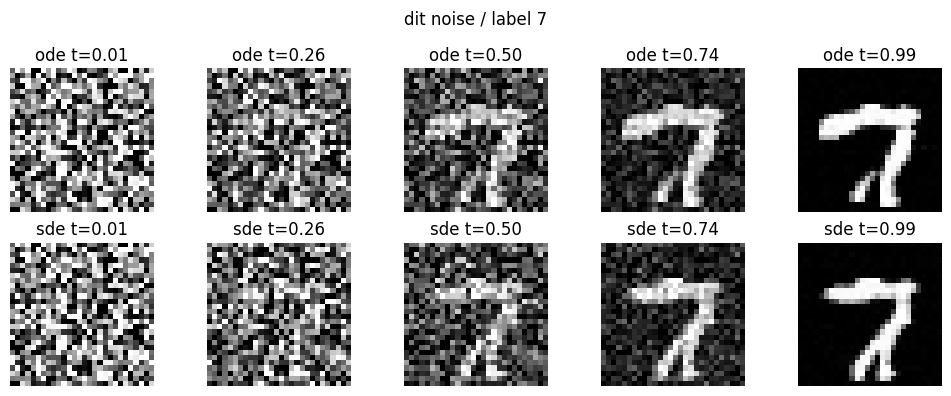

In [ ]:
for arch,kind in EXPERIMENTS:
    fig,axes=plt.subplots(2,5,figsize=(10,4))
    for row,solver in enumerate(['ode','sde']):
        saved=torch.load(RUN_DIR/f'{arch}_{kind}_{solver}_preview.pt',weights_only=True)
        for ax,frame,t in zip(axes[row],saved['trace'],saved['times']):
            ax.imshow(frame[7*COLS,0].clamp(-1,1),cmap='gray',vmin=-1,vmax=1)
            ax.set_title(f'{solver} t={t:.2f}'); ax.axis('off')
    fig.suptitle(f'{arch} {kind} / label 7'); plt.tight_layout(); plt.show()


## 9. 02와 동일한 pretrained evaluator
생성 학습에 사용하지 않는 공개 CNN으로 target-label accuracy를 측정한다. 02의 pinned revision·SHA256·전처리를 재사용한다. 실제 MNIST test accuracy ≥98% 검증을 통과해야 평가를 계속한다. CNN accuracy는 이미지 품질 전체를 뜻하지 않는다.

출처: [cmaeti/mnist-cnn](https://huggingface.co/cmaeti/mnist-cnn/tree/dd00ea6fffad752ea2dd9cebceebd95fa9cfbc95), Apache-2.0. 사전학습된 CNN만 사용하며 원격 Python 코드를 실행하지 않는다.


In [ ]:
# 8.2-A: evaluator 준비와 real MNIST sanity check (재학습 없음)
import hashlib, inspect, sys, subprocess
import pandas as pd
from IPython.display import display
try:
    from safetensors.torch import load_file
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'safetensors'])
    from safetensors.torch import load_file
import urllib.request

EVAL_REPO = 'cmaeti/mnist-cnn'
EVAL_REV = 'dd00ea6fffad752ea2dd9cebceebd95fa9cfbc95'
EVAL_WEIGHTS = RUN_DIR / 'evaluation_tools/mnist-cnn.safetensors'
EVAL_WEIGHTS.parent.mkdir(parents=True, exist_ok=True)
if not EVAL_WEIGHTS.exists():
    urllib.request.urlretrieve(
        f'https://huggingface.co/{EVAL_REPO}/resolve/{EVAL_REV}/mnist-cnn.safetensors',
        EVAL_WEIGHTS.with_suffix('.download'))
    os.replace(EVAL_WEIGHTS.with_suffix('.download'), EVAL_WEIGHTS)
EVAL_WEIGHT_SHA = hashlib.sha256(EVAL_WEIGHTS.read_bytes()).hexdigest()
assert EVAL_WEIGHT_SHA == 'ee8326a4b31466822379c10921f77d2e56dc6dea6a35fc2c49230e3393ae00e2', 'Evaluator weights checksum mismatch'

# Architecture adapted from the source repository's demo/app.py (Apache-2.0).
class EvaluationCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1,32,3,1)
        self.conv2 = nn.Conv2d(32,64,3,1)
        self.dropout1 = nn.Dropout(.25)
        self.dropout2 = nn.Dropout(.5)
        self.fc1 = nn.Linear(9216,128)
        self.fc2 = nn.Linear(128,10)
    def forward(self,x,return_features=False):
        x=F.relu(self.conv1(x)); x=F.relu(self.conv2(x))
        x=self.dropout1(F.max_pool2d(x,2)).flatten(1)
        features=F.relu(self.fc1(x))
        logits=self.fc2(self.dropout2(features))
        return (logits,features) if return_features else logits

evaluator=EvaluationCNN().to(device)
evaluator.load_state_dict(load_file(str(EVAL_WEIGHTS)),strict=True)
evaluator.eval().requires_grad_(False)

@torch.no_grad()
def eval_images(raw):
    # Our images are [-1,1]; classifier training used MNIST mean/std on [0,1].
    x=(raw.reshape(-1,1,28,28).to(device).clamp(-1,1)+1)/2
    return evaluator((x-.1307)/.3081,return_features=True)

eval_test_correct=torch.zeros(10,dtype=torch.long)
eval_test_total=torch.zeros(10,dtype=torch.long)
for real,label in test_loader:
    logits,_=eval_images(real)
    pred=logits.argmax(1).cpu(); label=label.cpu()
    eval_test_total+=torch.bincount(label,minlength=10)
    eval_test_correct+=torch.bincount(label[pred==label],minlength=10)
EVAL_REAL_ACC=(eval_test_correct.sum()/eval_test_total.sum()).item()
print(f'Pretrained evaluator: MNIST test accuracy = {EVAL_REAL_ACC:.2%}')
display(pd.DataFrame({'label':range(10),'real_test_accuracy':(eval_test_correct/eval_test_total).numpy()}))
assert EVAL_REAL_ACC>=.98, 'Evaluator sanity check failed; stop and check weights/preprocessing.'


Pretrained evaluator: MNIST test accuracy = 99.17%


,label,real_test_accuracy
0,0,0.995918
1,1,0.997357
2,2,0.994186
3,3,0.994059
4,4,0.992872
5,5,0.991031
6,6,0.986430
7,7,0.991245
8,8,0.990760
9,9,0.982161


### 9.1 정량 평가
기본값은 class당 100장, w=1/2/4, ODE/SDE. 선택한 모델 하나당 6,000장을 생성하므로 시간이 걸린다.

95% Wilson interval은 각 설정 accuracy의 표본 불확실성이며 설정 간 차이의 paired significance 검정은 아니다. Within-class feature spread는 같은 label의 feature variance 평균이다. 깨진 이미지도 spread를 늘릴 수 있어 real MNIST의 값 및 시각 평가와 함께 본다. Mean clipping amount는 범위 밖 pixel의 평균 초과량이다.


In [ ]:
EVAL_PER_CLASS=100
EVAL_WS=[1.,2.,4.]
EVAL_BATCH=64
EVAL_SDE_SEEDS=[2026]  # 최종 확인 시 [2026,2027,2028]로 확장

def wilson(k,n):
    p=k/n; z=1.96; d=1+z*z/n
    center=(p+z*z/(2*n))/d
    radius=z*math.sqrt(p*(1-p)/n+z*z/(4*n*n))/d
    return center-radius,center+radius

@torch.no_grad()
def metrics(raw,y):
    logits=[]; feats=[]
    for chunk in raw.split(256):
        l,f=eval_images(chunk); logits.append(l.cpu()); feats.append(f.cpu())
    pred=torch.cat(logits).argmax(1); features=torch.cat(feats)
    correct=pred==y; lo,hi=wilson(int(correct.sum()),len(y))
    spread=torch.stack([features[y==c].var(0,unbiased=False).mean() for c in range(10)]).mean()
    return dict(accuracy=correct.float().mean().item(),ci_low=lo,ci_high=hi,
                feature_spread=spread.item(),mean_clipping=(raw-raw.clamp(-1,1)).abs().mean().item()),correct

# 실제 test set 기준 feature spread (generated sample과 sample 수가 달라 절대 품질 척도 아님)
real=torch.cat([z for z,_ in test_loader]); real_y=torch.cat([y for _,y in test_loader])
print('Real MNIST reference:',metrics(real,real_y)[0])
del real,real_y

y_eval=torch.arange(10).repeat_interleave(EVAL_PER_CLASS)
x_eval=torch.randn(len(y_eval),1,28,28,generator=torch.Generator().manual_seed(4242))
records=[]; class_records=[]
for arch,kind in EXPERIMENTS:
    model,epoch=load_model(arch,kind)
    checkpoint_sha=hashlib.sha256(best_ckpt_path(arch,kind).read_bytes()).hexdigest()
    for solver,steps in [('ode',100),('sde',200)]:
        for sde_seed in ([2026] if solver=='ode' else EVAL_SDE_SEEDS):
            for w in EVAL_WS:
                spec=dict(arch=arch,kind=kind,checkpoint='best',checkpoint_sha=checkpoint_sha,epoch=epoch,
                    solver=solver,steps=steps,w=w,kappa=.5,t0=.01,t1=.99,
                    n=EVAL_PER_CLASS,x_seed=4242,sde_seed=sde_seed,batch=EVAL_BATCH,
                    evaluator_sha=EVAL_WEIGHT_SHA,sampler_version='lab03_v1')
                key=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()[:20]
                cache=RUN_DIR/'evaluation'/f'{key}.pt'
                if cache.exists():
                    saved=torch.load(cache,weights_only=True); assert saved['spec']==spec; raw=saved['raw']
                else:
                    chunks=[]; synchronize(); tic=time.perf_counter()
                    for j in range(0,len(y_eval),EVAL_BATCH):
                        out,_,_=sample(model,kind,x_eval[j:j+EVAL_BATCH],y_eval[j:j+EVAL_BATCH],
                            w=w,sampler=solver,steps=steps,seed=sde_seed+j)
                        chunks.append(out)
                    raw=torch.cat(chunks); synchronize()
                    atomic_save(dict(raw=raw,labels=y_eval,spec=spec,seconds=time.perf_counter()-tic),cache)
                stats,correct=metrics(raw,y_eval)
                records.append(dict(arch=arch,kind=kind,epoch=epoch,sampler=solver,w=w,seed=sde_seed,**stats))
                for c in range(10):
                    class_records.append(dict(arch=arch,kind=kind,sampler=solver,w=w,seed=sde_seed,
                        label=c,accuracy=correct[y_eval==c].float().mean().item()))
                print(records[-1],flush=True)
    del model; gc.collect()
    if device.type=='cuda': torch.cuda.empty_cache()
results=pd.DataFrame(records); per_class=pd.DataFrame(class_records)
results.to_csv(RUN_DIR/'evaluation_summary.csv',index=False)
per_class.to_csv(RUN_DIR/'evaluation_per_class.csv',index=False)
print("Evaluation complete; run the graph cell below.")


Real MNIST reference: {'accuracy': 0.9916999936103821, 'ci_low': 0.9897233048004503, 'ci_high': 0.993299057328914, 'feature_spread': 0.5986987352371216, 'mean_clipping': 0.0}
{'arch': 'unet', 'kind': 'flow', 'epoch': 30, 'sampler': 'ode', 'w': 1.0, 'seed': 2026, 'accuracy': 0.9399999976158142, 'ci_low': 0.9235285893693421, 'ci_high': 0.9531037398746343, 'feature_spread': 0.6660815477371216, 'mean_clipping': 0.0012258589267730713}
{'arch': 'unet', 'kind': 'flow', 'epoch': 30, 'sampler': 'ode', 'w': 2.0, 'seed': 2026, 'accuracy': 1.0, 'ci_low': 0.9961731014136095, 'ci_high': 1.0, 'feature_spread': 0.4713854193687439, 'mean_clipping': 0.0016993364552035928}
{'arch': 'unet', 'kind': 'flow', 'epoch': 30, 'sampler': 'ode', 'w': 4.0, 'seed': 2026, 'accuracy': 1.0, 'ci_low': 0.9961731014136095, 'ci_high': 1.0, 'feature_spread': 0.3830949068069458, 'mean_clipping': 0.0030642813071608543}
{'arch': 'unet', 'kind': 'flow', 'epoch': 30, 'sampler': 'sde', 'w': 1.0, 'seed': 2026, 'accuracy': 0.947000

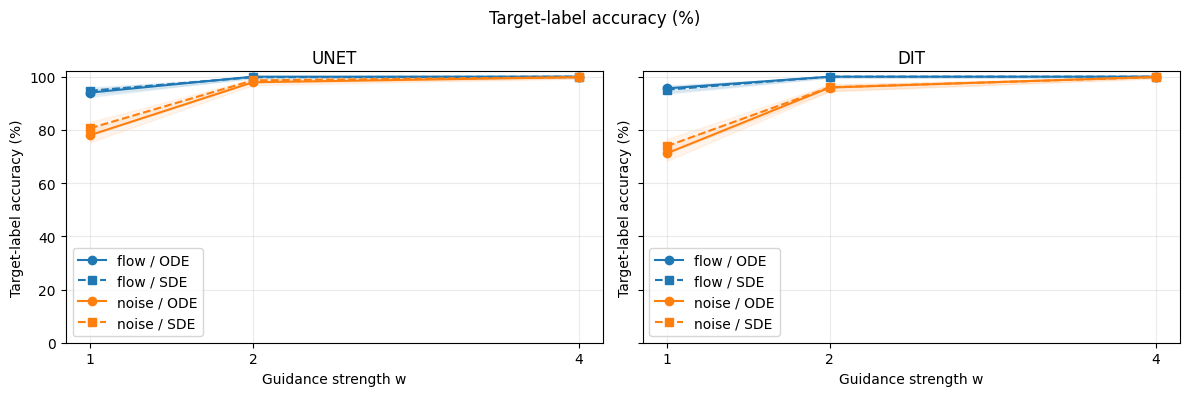

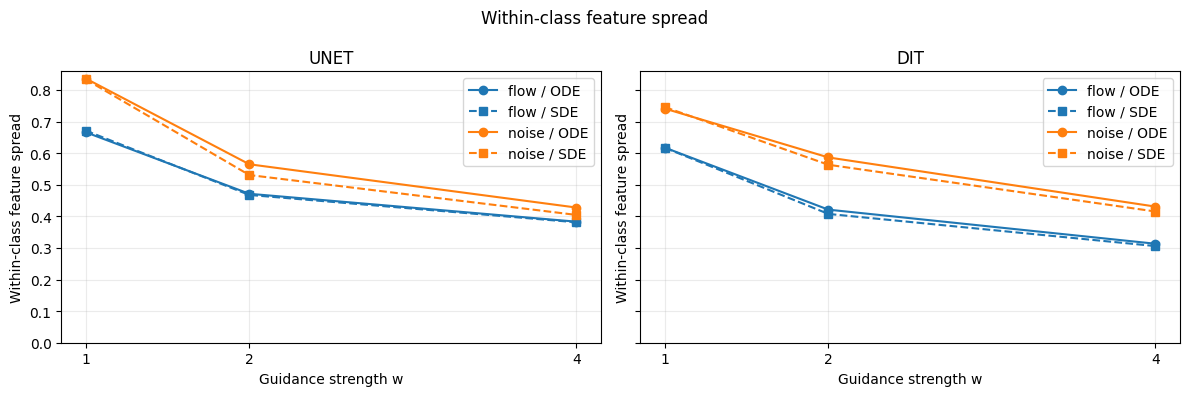

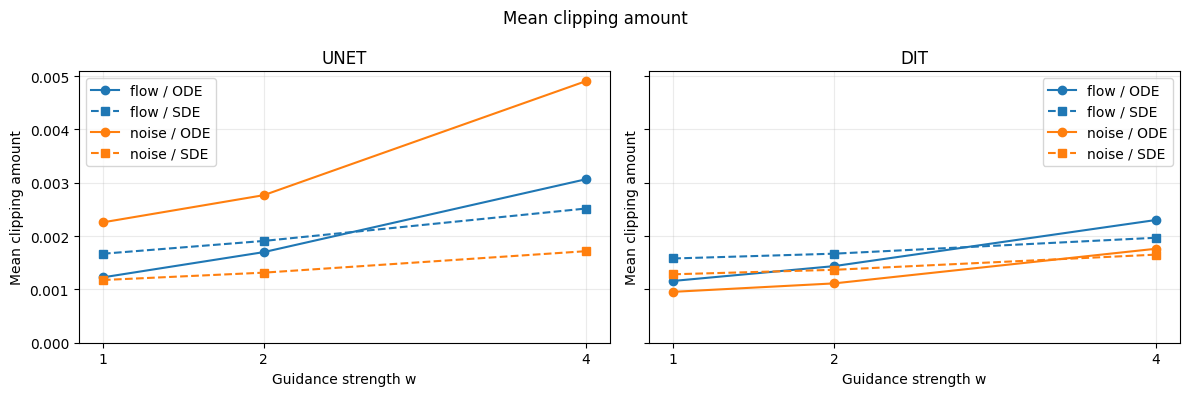

In [ ]:
SAVED_EVALUATION = [{'arch': 'unet', 'kind': 'flow', 'epoch': 30, 'sampler': 'ode', 'w': 1.0, 'seed': 2026, 'accuracy': 0.9399999976158142, 'ci_low': 0.9235285893693421, 'ci_high': 0.9531037398746343, 'feature_spread': 0.6660815477371216, 'mean_clipping': 0.0012258589267730713}, {'arch': 'unet', 'kind': 'flow', 'epoch': 30, 'sampler': 'ode', 'w': 2.0, 'seed': 2026, 'accuracy': 1.0, 'ci_low': 0.9961731014136095, 'ci_high': 1.0, 'feature_spread': 0.4713854193687439, 'mean_clipping': 0.0016993364552035928}, {'arch': 'unet', 'kind': 'flow', 'epoch': 30, 'sampler': 'ode', 'w': 4.0, 'seed': 2026, 'accuracy': 1.0, 'ci_low': 0.9961731014136095, 'ci_high': 1.0, 'feature_spread': 0.3830949068069458, 'mean_clipping': 0.0030642813071608543}, {'arch': 'unet', 'kind': 'flow', 'epoch': 30, 'sampler': 'sde', 'w': 1.0, 'seed': 2026, 'accuracy': 0.9470000267028809, 'ci_low': 0.9313250610861062, 'ci_high': 0.9592536915776607, 'feature_spread': 0.6712323427200317, 'mean_clipping': 0.0016688876785337925}, {'arch': 'unet', 'kind': 'flow', 'epoch': 30, 'sampler': 'sde', 'w': 2.0, 'seed': 2026, 'accuracy': 0.9980000257492065, 'ci_low': 0.9927370411104123, 'ci_high': 0.9994513678975429, 'feature_spread': 0.46768778562545776, 'mean_clipping': 0.0019091027788817883}, {'arch': 'unet', 'kind': 'flow', 'epoch': 30, 'sampler': 'sde', 'w': 4.0, 'seed': 2026, 'accuracy': 1.0, 'ci_low': 0.9961731014136095, 'ci_high': 1.0, 'feature_spread': 0.3811693787574768, 'mean_clipping': 0.0025160997174680233}, {'arch': 'dit', 'kind': 'flow', 'epoch': 30, 'sampler': 'ode', 'w': 1.0, 'seed': 2026, 'accuracy': 0.9559999704360962, 'ci_low': 0.9414479081796453, 'ci_high': 0.9670619603095666, 'feature_spread': 0.6173324584960938, 'mean_clipping': 0.0011589647037908435}, {'arch': 'dit', 'kind': 'flow', 'epoch': 30, 'sampler': 'ode', 'w': 2.0, 'seed': 2026, 'accuracy': 1.0, 'ci_low': 0.9961731014136095, 'ci_high': 1.0, 'feature_spread': 0.42116349935531616, 'mean_clipping': 0.0014366848627105355}, {'arch': 'dit', 'kind': 'flow', 'epoch': 30, 'sampler': 'ode', 'w': 4.0, 'seed': 2026, 'accuracy': 1.0, 'ci_low': 0.9961731014136095, 'ci_high': 1.0, 'feature_spread': 0.3132806420326233, 'mean_clipping': 0.0023015837650746107}, {'arch': 'dit', 'kind': 'flow', 'epoch': 30, 'sampler': 'sde', 'w': 1.0, 'seed': 2026, 'accuracy': 0.9509999752044678, 'ci_low': 0.9358089847812472, 'ci_high': 0.9627391526938285, 'feature_spread': 0.6169723868370056, 'mean_clipping': 0.0015800043474882841}, {'arch': 'dit', 'kind': 'flow', 'epoch': 30, 'sampler': 'sde', 'w': 2.0, 'seed': 2026, 'accuracy': 1.0, 'ci_low': 0.9961731014136095, 'ci_high': 1.0, 'feature_spread': 0.4076235294342041, 'mean_clipping': 0.0016701134154573083}, {'arch': 'dit', 'kind': 'flow', 'epoch': 30, 'sampler': 'sde', 'w': 4.0, 'seed': 2026, 'accuracy': 1.0, 'ci_low': 0.9961731014136095, 'ci_high': 1.0, 'feature_spread': 0.3058607876300812, 'mean_clipping': 0.001968635944649577}, {'arch': 'unet', 'kind': 'noise', 'epoch': 30, 'sampler': 'ode', 'w': 1.0, 'seed': 2026, 'accuracy': 0.8389999866485596, 'ci_low': 0.8149295245985896, 'ci_high': 0.8604758381598377, 'feature_spread': 0.7865436673164368, 'mean_clipping': 0.0026588384062051773}, {'arch': 'unet', 'kind': 'noise', 'epoch': 30, 'sampler': 'ode', 'w': 2.0, 'seed': 2026, 'accuracy': 0.9879999756813049, 'ci_low': 0.9791425260718425, 'ci_high': 0.9931224209078404, 'feature_spread': 0.5326021909713745, 'mean_clipping': 0.0033613175619393587}, {'arch': 'unet', 'kind': 'noise', 'epoch': 30, 'sampler': 'ode', 'w': 4.0, 'seed': 2026, 'accuracy': 1.0, 'ci_low': 0.9961731014136095, 'ci_high': 1.0, 'feature_spread': 0.4195048213005066, 'mean_clipping': 0.005532429087907076}, {'arch': 'unet', 'kind': 'noise', 'epoch': 30, 'sampler': 'sde', 'w': 1.0, 'seed': 2026, 'accuracy': 0.8619999885559082, 'ci_low': 0.8392335563875687, 'ci_high': 0.8819957690358847, 'feature_spread': 0.7863765954971313, 'mean_clipping': 0.002628110349178314}, {'arch': 'unet', 'kind': 'noise', 'epoch': 30, 'sampler': 'sde', 'w': 2.0, 'seed': 2026, 'accuracy': 0.9909999966621399, 'ci_low': 0.982983992177176, 'ci_high': 0.9952579934109885, 'feature_spread': 0.525670051574707, 'mean_clipping': 0.0030872859060764313}, {'arch': 'unet', 'kind': 'noise', 'epoch': 30, 'sampler': 'sde', 'w': 4.0, 'seed': 2026, 'accuracy': 0.9980000257492065, 'ci_low': 0.9927370411104123, 'ci_high': 0.9994513678975429, 'feature_spread': 0.41210827231407166, 'mean_clipping': 0.004121950827538967}, {'arch': 'dit', 'kind': 'noise', 'epoch': 30, 'sampler': 'ode', 'w': 1.0, 'seed': 2026, 'accuracy': 0.7120000123977661, 'ci_low': 0.6831639454351635, 'ci_high': 0.7392134495642069, 'feature_spread': 0.7409900426864624, 'mean_clipping': 0.0009543946944177151}, {'arch': 'dit', 'kind': 'noise', 'epoch': 30, 'sampler': 'ode', 'w': 2.0, 'seed': 2026, 'accuracy': 0.9589999914169312, 'ci_low': 0.9448517110985959, 'ci_high': 0.9696351959990976, 'feature_spread': 0.5864139199256897, 'mean_clipping': 0.0011128076585009694}, {'arch': 'dit', 'kind': 'noise', 'epoch': 30, 'sampler': 'ode', 'w': 4.0, 'seed': 2026, 'accuracy': 0.9990000128746033, 'ci_low': 0.9943572970398398, 'ci_high': 0.9998234581709429, 'feature_spread': 0.4308178424835205, 'mean_clipping': 0.0017623704625293612}, {'arch': 'dit', 'kind': 'noise', 'epoch': 30, 'sampler': 'sde', 'w': 1.0, 'seed': 2026, 'accuracy': 0.7390000224113464, 'ci_low': 0.7109014620594993, 'ci_high': 0.765269280416206, 'feature_spread': 0.7457358241081238, 'mean_clipping': 0.0012836705427616835}, {'arch': 'dit', 'kind': 'noise', 'epoch': 30, 'sampler': 'sde', 'w': 2.0, 'seed': 2026, 'accuracy': 0.9599999785423279, 'ci_low': 0.9459900625744302, 'ci_high': 0.9704891907260906, 'feature_spread': 0.5632492899894714, 'mean_clipping': 0.0013674832880496979}, {'arch': 'dit', 'kind': 'noise', 'epoch': 30, 'sampler': 'sde', 'w': 4.0, 'seed': 2026, 'accuracy': 0.9980000257492065, 'ci_low': 0.9927370411104123, 'ci_high': 0.9994513678975429, 'feature_spread': 0.4152836799621582, 'mean_clipping': 0.0016521458746865392}]

# 저장된 CSV가 있으면 최신 결과를 사용. 없으면 이 노트북에 저장된 평가 snapshot 사용.
summary_path = RUN_DIR / 'evaluation_summary.csv'
plot_results = pd.read_csv(summary_path) if summary_path.exists() else pd.DataFrame(SAVED_EVALUATION)
colors = {'flow': 'tab:blue', 'noise': 'tab:orange'}
styles = {'ode': '-', 'sde': '--'}
metrics_to_plot = [('accuracy', 'Target-label accuracy (%)', 100),
                   ('feature_spread', 'Within-class feature spread', 1),
                   ('mean_clipping', 'Mean clipping amount', 1)]
arches = list(plot_results.arch.unique())
for metric, title, scale in metrics_to_plot:
    fig, axes = plt.subplots(1, len(arches), figsize=(6*len(arches), 4), squeeze=False, sharey=True)
    for ax, arch in zip(axes[0], arches):
        for (kind, sampler), group in plot_results[plot_results.arch == arch].groupby(['kind','sampler']):
            g = group.groupby('w', as_index=False)[metric].mean().sort_values('w')
            ax.plot(g.w, g[metric]*scale, color=colors[kind], linestyle=styles[sampler],
                    marker='o' if sampler=='ode' else 's', label=f'{kind} / {sampler.upper()}')
            # 한 seed일 때만 해당 설정의 Wilson interval 표시. seed 평균의 CI로 오해하지 않도록 함.
            if metric == 'accuracy' and group.groupby('w').size().max() == 1:
                q = group.sort_values('w')
                ax.fill_between(q.w, q.ci_low*100, q.ci_high*100, color=colors[kind], alpha=.08)
        ax.set(title=arch.upper(), xlabel='Guidance strength w', ylabel=title)
        ax.set_xticks(sorted(plot_results.w.unique())); ax.grid(alpha=.25); ax.legend()
        if metric=='accuracy': ax.set_ylim(0,102)
        else: ax.set_ylim(bottom=0)
    fig.suptitle(title + (' (seed mean)' if plot_results.groupby(['arch','kind','sampler','w']).size().max()>1 else ''))
    fig.tight_layout(); plt.show()


## 10. 실패 원인 분석: 한 번에 한 축만 바꾸기
1. **Noise만 약하다:** 아래 time별 implied-velocity MSE를 비교한다. 작은 t의 오차 증폭을 확인한다.
2. **SDE만 약하다:** w=1부터 kappa=0.1/0.5, SDE 200/400 steps, seed 3개로 비교한다. kappa=0 SDE는 Euler ODE이며 Heun과 같은 solver가 아니다.
3. **DiT가 늦게 배운다:** loss 추세와 동일 epoch/학습 시간을 함께 보고, 먼저 epoch를 늘린다.
4. **accuracy가 포화된다:** w를 가린 동일-noise 이미지로 획/배경/다양성을 비교한다.
5. **끝점 민감성:** 같은 checkpoint로 t0=0.01/0.02, t1=0.98/0.99를 비교한다. 초기분포·종료시간 근사도 달라지므로 sampler 우열로 단정하지 않는다.


In [ ]:
@torch.no_grad()
def time_diagnostic(m,kind):
    z,y=next(iter(val_loader)); z=z.to(device); y=y.to(device)
    eps=torch.randn(z.shape,generator=torch.Generator().manual_seed(71)).to(device)
    rows=[]
    for t in [.01,.05,.1,.25,.5,.75,.9,.99]:
        x=t*z+(1-t)*eps
        v=velocity(m,kind,x,t,y,w=1.)
        rows.append(dict(t=t,velocity_mse=F.mse_loss(v,z-eps).item()))
    return rows
time_records=[]
for arch,kind in EXPERIMENTS:
    model,epoch=load_model(arch,kind)
    time_records.extend(dict(arch=arch,kind=kind,**r) for r in time_diagnostic(model,kind))
    del model

time_results=pd.DataFrame(time_records)
time_results.to_csv(RUN_DIR/"time_diagnostic.csv", index=False)
print("Time diagnostic complete; run the graph cell below.")


Time diagnostic complete; run the graph cell below.


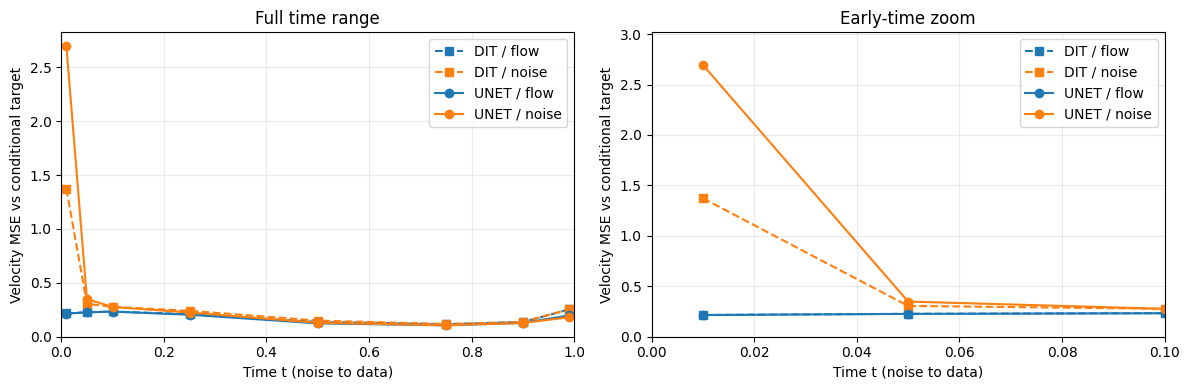

In [ ]:
SAVED_TIME_DIAGNOSTIC = [{'t': 0.01, 'velocity_mse': 0.214684, 'arch': 'unet', 'kind': 'flow'}, {'t': 0.05, 'velocity_mse': 0.226156, 'arch': 'unet', 'kind': 'flow'}, {'t': 0.1, 'velocity_mse': 0.2326, 'arch': 'unet', 'kind': 'flow'}, {'t': 0.25, 'velocity_mse': 0.204258, 'arch': 'unet', 'kind': 'flow'}, {'t': 0.5, 'velocity_mse': 0.123838, 'arch': 'unet', 'kind': 'flow'}, {'t': 0.75, 'velocity_mse': 0.105546, 'arch': 'unet', 'kind': 'flow'}, {'t': 0.9, 'velocity_mse': 0.128465, 'arch': 'unet', 'kind': 'flow'}, {'t': 0.99, 'velocity_mse': 0.19708, 'arch': 'unet', 'kind': 'flow'}, {'t': 0.01, 'velocity_mse': 0.215874, 'arch': 'dit', 'kind': 'flow'}, {'t': 0.05, 'velocity_mse': 0.227252, 'arch': 'dit', 'kind': 'flow'}, {'t': 0.1, 'velocity_mse': 0.233974, 'arch': 'dit', 'kind': 'flow'}, {'t': 0.25, 'velocity_mse': 0.209472, 'arch': 'dit', 'kind': 'flow'}, {'t': 0.5, 'velocity_mse': 0.137906, 'arch': 'dit', 'kind': 'flow'}, {'t': 0.75, 'velocity_mse': 0.11648, 'arch': 'dit', 'kind': 'flow'}, {'t': 0.9, 'velocity_mse': 0.137266, 'arch': 'dit', 'kind': 'flow'}, {'t': 0.99, 'velocity_mse': 0.252813, 'arch': 'dit', 'kind': 'flow'}, {'t': 0.01, 'velocity_mse': 2.262737, 'arch': 'unet', 'kind': 'noise'}, {'t': 0.05, 'velocity_mse': 0.317622, 'arch': 'unet', 'kind': 'noise'}, {'t': 0.1, 'velocity_mse': 0.260075, 'arch': 'unet', 'kind': 'noise'}, {'t': 0.25, 'velocity_mse': 0.215823, 'arch': 'unet', 'kind': 'noise'}, {'t': 0.5, 'velocity_mse': 0.127021, 'arch': 'unet', 'kind': 'noise'}, {'t': 0.75, 'velocity_mse': 0.107759, 'arch': 'unet', 'kind': 'noise'}, {'t': 0.9, 'velocity_mse': 0.1289, 'arch': 'unet', 'kind': 'noise'}, {'t': 0.99, 'velocity_mse': 0.196295, 'arch': 'unet', 'kind': 'noise'}, {'t': 0.01, 'velocity_mse': 1.372291, 'arch': 'dit', 'kind': 'noise'}, {'t': 0.05, 'velocity_mse': 0.305561, 'arch': 'dit', 'kind': 'noise'}, {'t': 0.1, 'velocity_mse': 0.276874, 'arch': 'dit', 'kind': 'noise'}, {'t': 0.25, 'velocity_mse': 0.240247, 'arch': 'dit', 'kind': 'noise'}, {'t': 0.5, 'velocity_mse': 0.149725, 'arch': 'dit', 'kind': 'noise'}, {'t': 0.75, 'velocity_mse': 0.117585, 'arch': 'dit', 'kind': 'noise'}, {'t': 0.9, 'velocity_mse': 0.137161, 'arch': 'dit', 'kind': 'noise'}, {'t': 0.99, 'velocity_mse': 0.25453, 'arch': 'dit', 'kind': 'noise'}]

# 10절 진단을 다시 실행했다면 새 결과, 아니면 저장된 표의 snapshot을 그림으로 표시.
diag_plot = time_results if 'time_results' in globals() else pd.DataFrame(SAVED_TIME_DIAGNOSTIC)
fig, axes = plt.subplots(1, 2, figsize=(12,4), sharey=False)
for (arch, kind), group in diag_plot.groupby(['arch','kind']):
    g = group.sort_values('t')
    for ax in axes:
        ax.plot(g.t, g.velocity_mse, color={'flow':'tab:blue','noise':'tab:orange'}[kind],
                linestyle='-' if arch=='unet' else '--', marker='o' if arch=='unet' else 's',
                label=f'{arch.upper()} / {kind}')
axes[0].set(title='Full time range', xlim=(0,1))
axes[1].set(title='Early-time zoom', xlim=(0,.1))
early = diag_plot.loc[diag_plot.t<=.1, 'velocity_mse']
axes[1].set_ylim(0, early.max()*1.12)
for ax in axes:
    ax.set(xlabel='Time t (noise to data)', ylabel='Velocity MSE vs conditional target')
    ax.set_ylim(bottom=0); ax.grid(alpha=.25); ax.legend()
fig.tight_layout(); plt.show()


### 10.1 초반 예측이 최종 결과에 영향을 주는가? — 모델 교체 실험

같은 architecture의 Flow/Noise checkpoint를 이용한다. 재학습 없이 **순수 Flow / 순수 Noise / Flow→Noise / Noise→Flow**를 비교한다. 교체 시점은 t=0.1, 시작/끝은 0.01/0.99다.

- 통제: 같은 initial noise·label·epoch·w·Heun 100 steps·시간 격자. 총 velocity 평가 200회(CFG branch forward 400회). 이 셀의 pure baseline을 사용한다. 기존 9절과 시간 격자가 조금 다르다.
- 아래 실험은 guidance strength를 설정해 실행할 수 있다. 11절에 기록한 모델 교체 결과는 w=2에서 얻었다. 모델당 label별 100장, 전체 1,000장씩 4조건을 생성한다. U-Net과 DiT를 모두 실행한다.
- 준비: 0–2, 3–4, 6절의 함수 정의, 7절, 9절 evaluator와 metrics 정의가 런타임에 필요하다. 재연결했다면 TRAIN=False로 설정하고 준비 셀 실행. 9.1 전체 재생성은 필요 없으며 metrics 함수 정의까지만 실행해도 된다.
- 같은 행은 같은 label·initial noise이며 각 label에서 두 sample을 보여준다. 전체 accuracy·feature spread·clipping은 그래프로 비교하고 pure Noise 대비 정답 변화 수를 출력한다.
- Flow→Noise가 pure Noise보다 좋아지면 초반 field를 교체하는 개입이 도움이 됐다는 근거다. Noise→Flow도 좋아지면 후반 field의 영향도 있다. 둘 다 고려하고 이미지 품질도 함께 본다.
- 서로 다른 모델을 섞으므로 field 간 불일치가 생길 수 있다. 실패해도 초반 오차 가설을 즉시 기각하지 않는다. Wilson interval은 개별 accuracy 구간이며 paired difference 유의성 검정이 아니다.

아래 셀을 실행하면 순수 Flow, 순수 Noise와 두 모델 교체 조건을 비교한다.

unet | Flow only | w=2: accuracy=100.0%
unet | Noise only | w=2: accuracy=97.8%
unet | Flow -> Noise | w=2: accuracy=99.9%
unet | Noise -> Flow | w=2: accuracy=99.9%
Flow -> Noise vs Noise only: wrong -> right=21, right -> wrong=0
Noise -> Flow vs Noise only: wrong -> right=22, right -> wrong=1


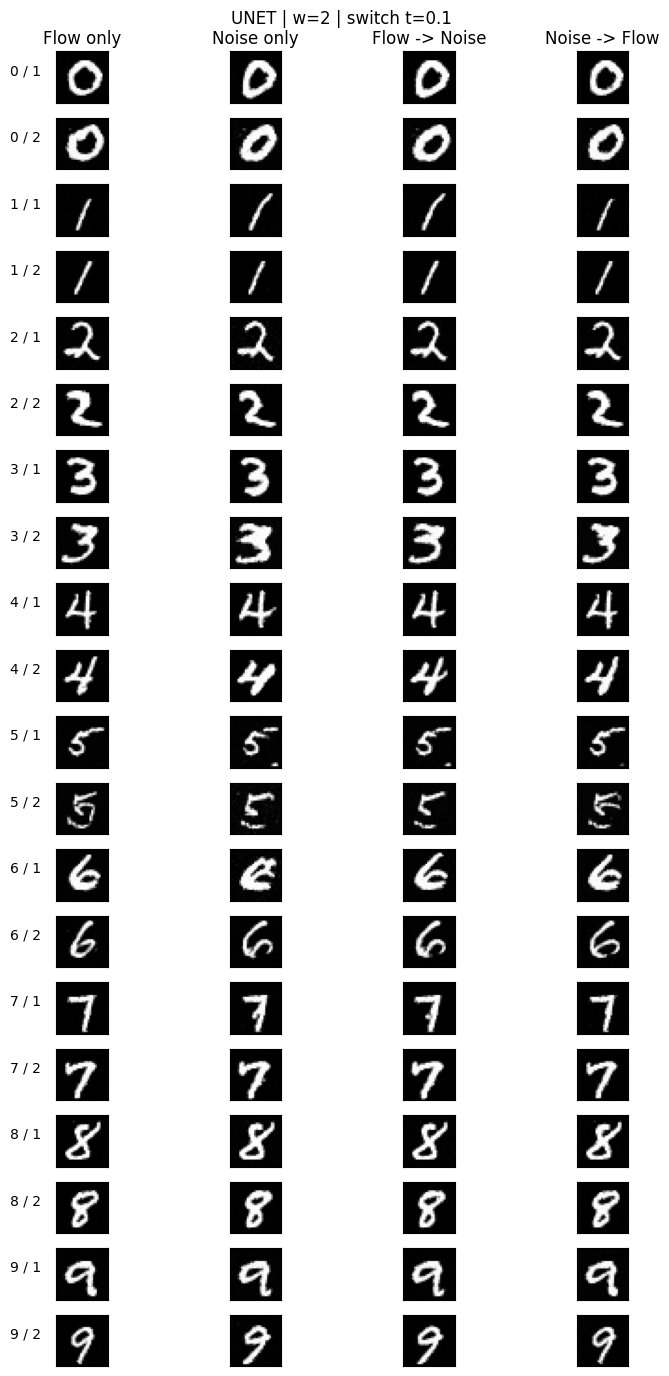

unet | Flow only | w=4: accuracy=100.0%
unet | Noise only | w=4: accuracy=99.8%
unet | Flow -> Noise | w=4: accuracy=100.0%
unet | Noise -> Flow | w=4: accuracy=100.0%
Flow -> Noise vs Noise only: wrong -> right=2, right -> wrong=0
Noise -> Flow vs Noise only: wrong -> right=2, right -> wrong=0


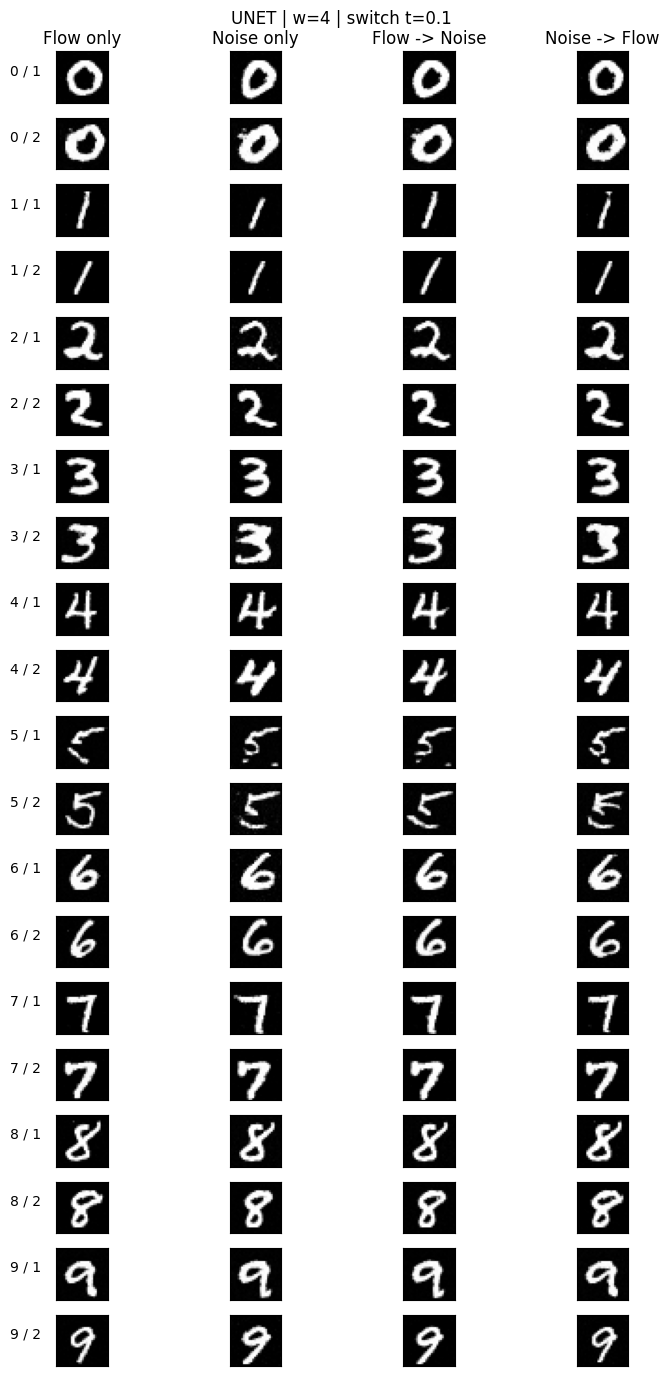

dit | Flow only | w=2: accuracy=100.0%
dit | Noise only | w=2: accuracy=95.9%
dit | Flow -> Noise | w=2: accuracy=98.7%
dit | Noise -> Flow | w=2: accuracy=99.7%
Flow -> Noise vs Noise only: wrong -> right=29, right -> wrong=1
Noise -> Flow vs Noise only: wrong -> right=40, right -> wrong=2


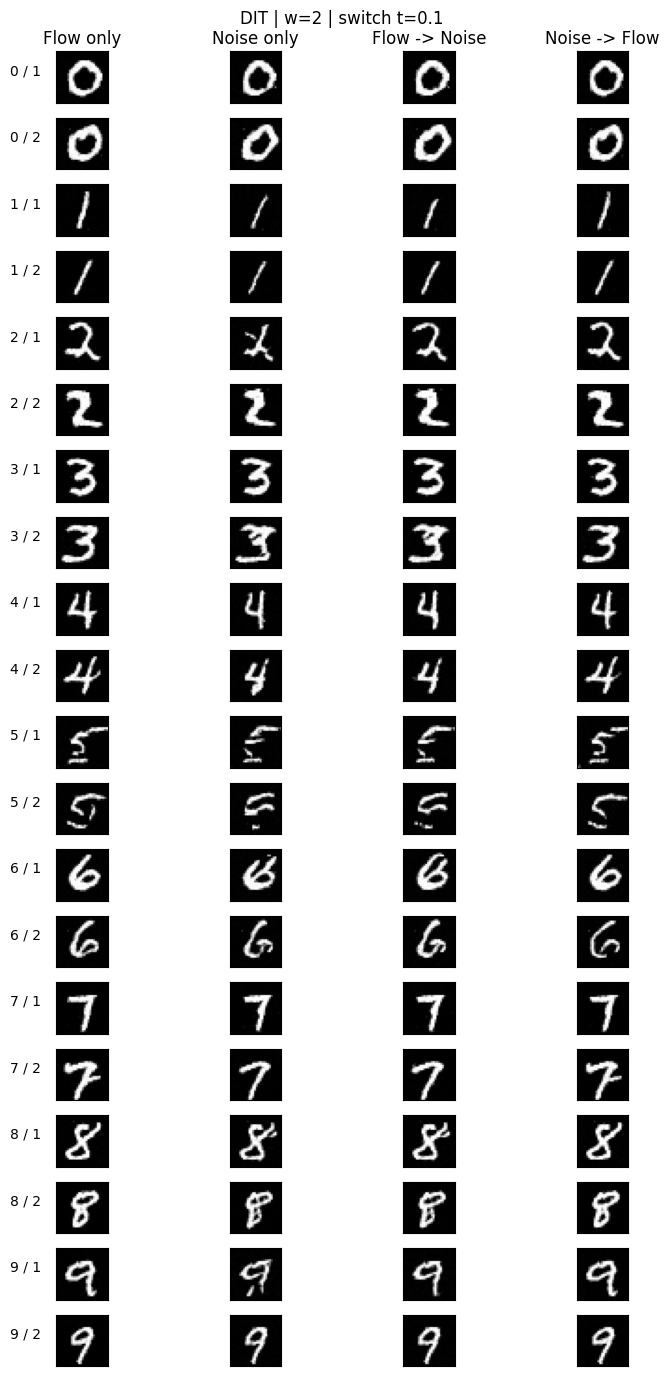

dit | Flow only | w=4: accuracy=100.0%
dit | Noise only | w=4: accuracy=99.8%
dit | Flow -> Noise | w=4: accuracy=100.0%
dit | Noise -> Flow | w=4: accuracy=100.0%
Flow -> Noise vs Noise only: wrong -> right=2, right -> wrong=0
Noise -> Flow vs Noise only: wrong -> right=2, right -> wrong=0


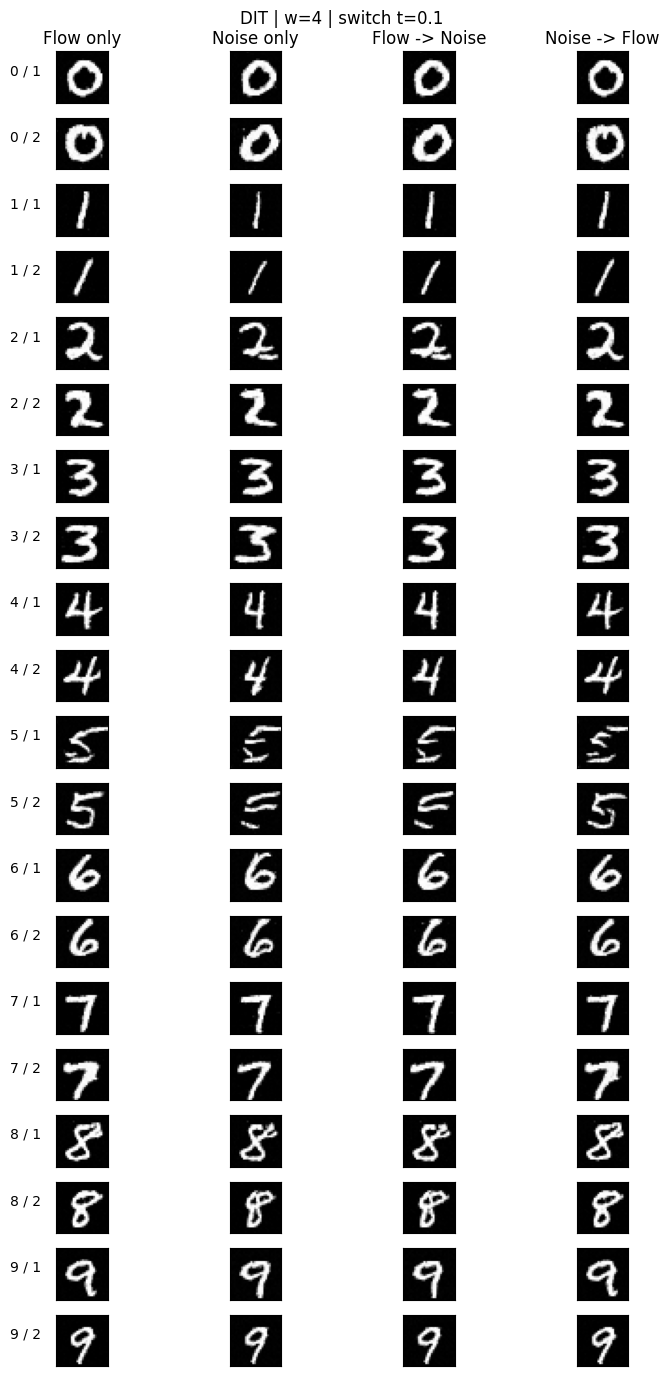

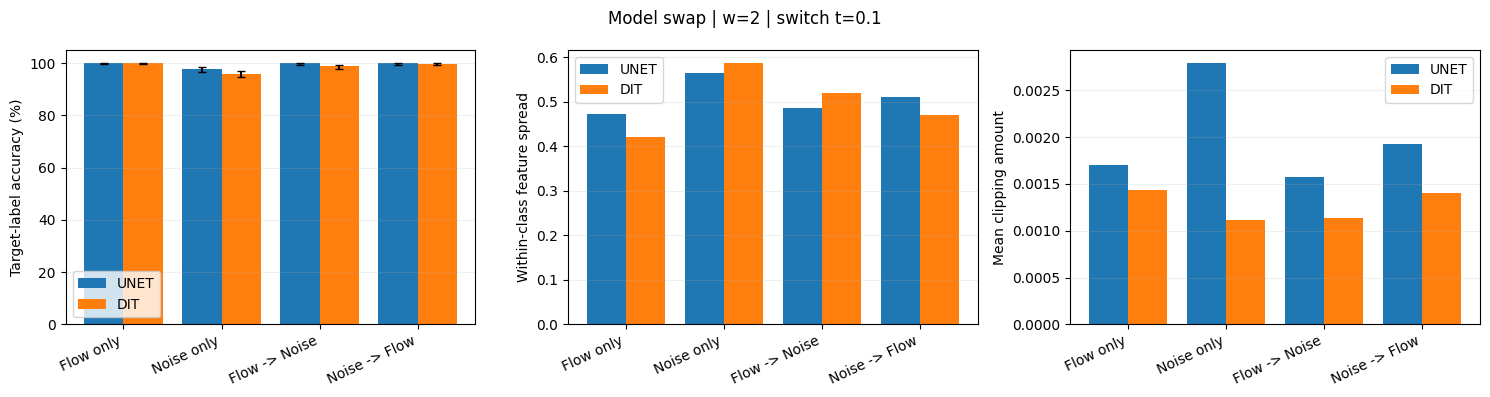

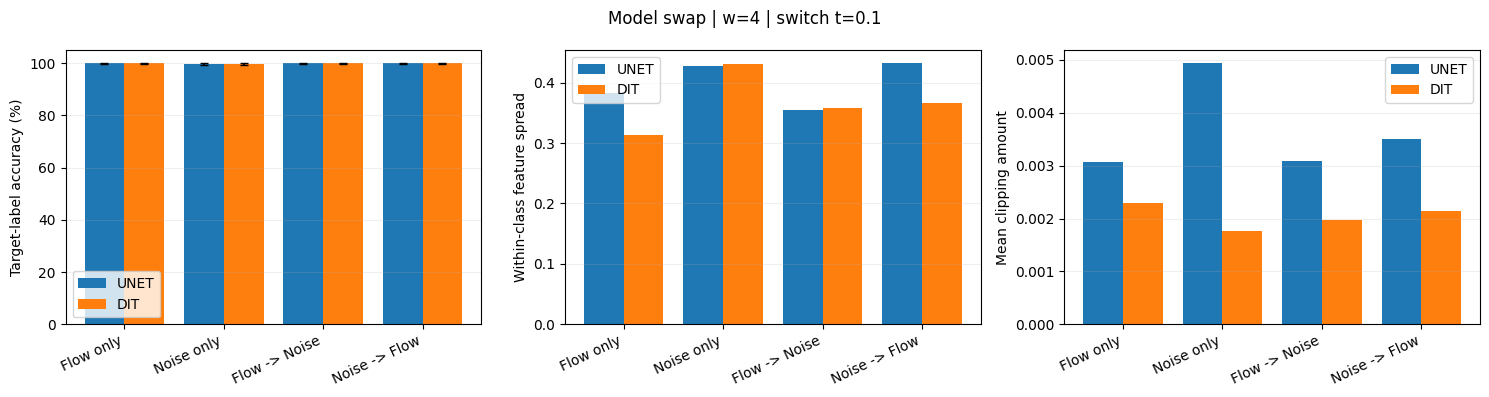

In [ ]:
# 10.1 Early / late model swap: no training, same initial noise and Heun grid
SWAP_ARCHES = ['unet', 'dit']
SWAP_WS = [2.,4.]
SWAP_PER_CLASS = 100           # 빠른 확인은 20
SWAP_BATCH = 64
SWAP_T = .1
SWAP_STEPS = 100
SWAP_SEED = 4242
SWAP_CASES = [('Flow only','flow','flow'), ('Noise only','noise','noise'),
              ('Flow -> Noise','flow','noise'), ('Noise -> Flow','noise','flow')]

@torch.no_grad()
def sample_swap(models, x0, y, early, late, w, switch=.1, steps=100):
    t0, t1 = .01, .99
    assert t0 < switch < t1 and steps >= 2
    n_early = max(1, min(steps-1, round(steps*(switch-t0)/(t1-t0))))
    # 모든 비교군이 같은 격자 사용. 경계에서 Heun의 두 평가 모두 해당 구간 모델 사용.
    segments = [(np.linspace(t0,switch,n_early+1),early),
                (np.linspace(switch,t1,steps-n_early+1),late)]
    x=x0.to(device).clone(); y=y.to(device)
    for times,kind in segments:
        for t,tn in zip(times[:-1],times[1:]):
            h=float(tn-t)
            v=velocity(models[kind],kind,x,float(t),y,w)
            v2=velocity(models[kind],kind,x+h*v,float(tn),y,w)
            x=x+.5*h*(v+v2)
            if not torch.isfinite(x).all(): raise RuntimeError('Non-finite hybrid sample')
    return x.cpu()

swap_y=torch.arange(10).repeat_interleave(SWAP_PER_CLASS)
swap_x=torch.randn(len(swap_y),1,28,28,generator=torch.Generator().manual_seed(SWAP_SEED))
swap_records=[]
for arch in SWAP_ARCHES:
    for kind in ['flow','noise']:
        if not best_ckpt_path(arch,kind).exists():
            raise FileNotFoundError(f'{arch} {kind} checkpoint required; change SWAP_ARCHES if needed')
    models={}; epochs={}
    for kind in ['flow','noise']:
        models[kind],epochs[kind]=load_model(arch,kind)
    hashes={k:hashlib.sha256(best_ckpt_path(arch,k).read_bytes()).hexdigest() for k in models}
    for w in SWAP_WS:
        raw_by_case={}; correct_by_case={}
        for name,early,late in SWAP_CASES:
            spec=dict(version='early_swap_v2',checkpoint='best',arch=arch,hashes=hashes,epochs=epochs,
                      early=early,late=late,w=w,switch=SWAP_T,steps=SWAP_STEPS,
                      t0=.01,t1=.99,seed=SWAP_SEED,n=SWAP_PER_CLASS,batch=SWAP_BATCH)
            key=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()[:20]
            cache=RUN_DIR/'early_swap'/f'{key}.pt'
            if cache.exists():
                saved=torch.load(cache,weights_only=True)
                assert saved['spec']==spec
                raw=saved['raw']
            else:
                raw=torch.cat([sample_swap(models,swap_x[j:j+SWAP_BATCH],swap_y[j:j+SWAP_BATCH],
                        early,late,w,SWAP_T,SWAP_STEPS) for j in range(0,len(swap_y),SWAP_BATCH)])
                atomic_save(dict(raw=raw,labels=swap_y,spec=spec),cache)
            stats,correct=metrics(raw,swap_y)
            raw_by_case[name]=raw; correct_by_case[name]=correct
            swap_records.append(dict(arch=arch,w=w,case=name,flow_epoch=epochs['flow'],noise_epoch=epochs['noise'],**stats))
            print(f'{arch} | {name} | w={w:g}: accuracy={stats["accuracy"]:.1%}',flush=True)
        # paired outcomes relative to pure Noise, same initial samples
        base=correct_by_case['Noise only']
        for name in ['Flow -> Noise','Noise -> Flow']:
            changed=correct_by_case[name]
            print(f'{name} vs Noise only: wrong -> right={int((~base & changed).sum())}, '
                  f'right -> wrong={int((base & ~changed).sum())}')
        # 2 fixed examples per label; each row is the same label and initial noise across cases
        preview_idx=[c*SWAP_PER_CLASS+j for c in range(10) for j in range(min(2,SWAP_PER_CLASS))]
        fig,axes=plt.subplots(len(preview_idx),4,figsize=(8, .7*len(preview_idx)),squeeze=False)
        for col,(name,_,_) in enumerate(SWAP_CASES):
            for row,idx in enumerate(preview_idx):
                axes[row,col].imshow(raw_by_case[name][idx,0].clamp(-1,1),cmap='gray',vmin=-1,vmax=1)
                axes[row,col].set_xticks([]); axes[row,col].set_yticks([])
                if col==0: axes[row,col].set_ylabel(f'{int(swap_y[idx])} / {row%2+1}',rotation=0,labelpad=22)
                if row==0: axes[row,col].set_title(name)
        fig.suptitle(f'{arch.upper()} | w={w:g} | switch t={SWAP_T}')
        fig.tight_layout(); plt.show()
    del models; gc.collect()
    if device.type=='cuda': torch.cuda.empty_cache()
swap_results=pd.DataFrame(swap_records)
swap_results.to_csv(RUN_DIR/'early_swap_summary.csv',index=False)
for w in SWAP_WS:
    fig,axes=plt.subplots(1,3,figsize=(15,4))
    for ax,metric,title,factor in zip(axes,['accuracy','feature_spread','mean_clipping'],
            ['Target-label accuracy (%)','Within-class feature spread','Mean clipping amount'],[100,1,1]):
        names=[x[0] for x in SWAP_CASES]; positions=np.arange(4)
        width=.8/len(SWAP_ARCHES)
        for j,arch in enumerate(SWAP_ARCHES):
            g=swap_results[(swap_results.arch==arch)&(swap_results.w==w)].set_index('case').loc[names]
            xp=positions+(j-(len(SWAP_ARCHES)-1)/2)*width
            ax.bar(xp,g[metric]*factor,width=width,label=arch.upper())
            if metric=='accuracy':
                err=np.maximum(0,np.vstack([g.accuracy-g.ci_low,g.ci_high-g.accuracy])*100)
                ax.errorbar(xp,g.accuracy*100,yerr=err,fmt='none',color='black',capsize=3)
        ax.set_xticks(positions,names,rotation=25,ha='right')
        ax.set_ylabel(title); ax.set_ylim(bottom=0); ax.grid(axis='y',alpha=.2);ax.legend()
        if metric=='accuracy':ax.set_ylim(0,105)
    fig.suptitle(f'Model swap | w={w:g} | switch t={SWAP_T}')
    fig.tight_layout();plt.show()


## 11. 결론

### U-Net과 DiT를 이용한 이미지 생성

U-Net과 DiT를 구현하고, 같은 선형 probability path에서 Flow와 Noise prediction을 각각 학습했다. 두 architecture 모두 숫자를 식별할 수 있는 MNIST 이미지를 생성했으며, 이전 MLP 실험보다 시각적으로 뚜렷한 결과를 얻었다.

### 이번 설정에서는 Flow가 더 높은 생성 정확도를 보였다

모델 교체 실험의 순수 모델 기준으로, guidance strength가 w=2일 때 Flow의 target-label accuracy는 U-Net과 DiT 모두 100%였다. Noise는 각각 97.8%, 95.9%였다. w=4에서는 Noise도 두 architecture 모두 99.8%에 도달하여 정확도 차이가 줄었다.

이는 이번 설정에서 Flow 모델이 원하는 숫자로 분류되는 이미지를 더 안정적으로 생성했다는 뜻이다. 다만 label accuracy만으로 획의 깔끔함과 이미지의 다양성까지 판단할 수는 없으므로, 생성 이미지와 feature spread도 함께 살펴봐야 한다.

### Noise의 초반 velocity 오차는 컸지만, 성능 차이의 원인을 초반으로만 좁히지는 못했다

시간별 진단에서는 Noise 모델의 출력을 velocity로 변환했을 때 생성 초반의 오차가 크게 나타났다. 이번 선형 경로에서는 다음 관계가 성립한다.

$$
\hat v=\frac{x_t-\hat\epsilon}{t},
\qquad
\|\hat\epsilon-\epsilon\|^2
=t^2\|\hat v-(z-\epsilon)\|^2
$$

따라서 Noise MSE는 velocity 관점에서 작은 t의 오차를 상대적으로 약하게 반영한다. 반면 Flow는 velocity를 직접 학습한다. 이 학습 목표의 차이는 두 모델의 생성 성능이 달라진 이유를 설명할 수 있는 후보이다.

초반 구간만 Flow로 바꾼 실험에서는 순수 Noise보다 label accuracy가 높아졌다. 그러나 초반을 Noise로 유지하고 후반만 Flow로 바꿔도 개선되었다.

| 생성 방식 — w=2 | U-Net | DiT |
|---|---:|---:|
| Flow only | 100.0% | 100.0% |
| Noise only | 97.8% | 95.9% |
| Flow → Noise | 99.9% | 98.7% |
| Noise → Flow | 99.9% | 99.7% |

모델 교체 시점은 t=0.1이며, 각 조건에서 같은 초기 noise와 label로 1,000장을 생성했다.

이 결과는 초반 구간을 Flow로 대체하는 것이 도움이 된다는 점을 보여준다. 동시에 후반에 Flow를 사용하는 것만으로도 개선될 수 있으므로, 최종 성능 차이를 초반 오차만으로 설명할 수는 없다. 이번 실험에서는 Flow의 어느 구간을 사용하느냐에 따른 효과를 확인했으며, Flow가 더 좋은 결과를 얻은 원인을 하나로 확정하지는 않았다.

### 실험의 범위

이번 실험은 **동일한 선형 probability path에서 velocity prediction과 noise prediction을 비교한 실험**이다.

또한 같은 학습 모델을 ODE와 SDE sampling에 모두 사용할 수 있음을 구현으로 확인했다. 학습 target과 sampling 방식은 별개의 선택이며, 생성 결과는 architecture, 학습 목표, guidance 강도, 수치 적분 방법이 함께 결정한다.


## Reference
- [U-Net, Ronneberger et al. (2015)](https://arxiv.org/abs/1505.04597): encoder–decoder와 skip connection.
- [DiT, Peebles & Xie (2023)](https://arxiv.org/abs/2212.09748), [공식 구현](https://github.com/facebookresearch/DiT): patch Transformer와 adaLN-Zero. 본 구현은 작은 pixel-space 변형.
- [Flow Matching, Lipman et al. (2023)](https://arxiv.org/abs/2210.02747).
- [MIT Flow Matching and Diffusion Models](https://diffusion.csail.mit.edu/): Gaussian path, score–velocity 관계, guidance와 SDE.
- [PyTorch MultiheadAttention](https://docs.pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html).